# Broadband DOE beam shaper: 1D radial design → 2D ASM layouts → 2D refinement

This notebook designs a phase-only diffractive optical element (DOE) that converts a Gaussian input beam into a circular, approximately flat-top focal-plane irradiance over a band of frequencies.

The workflow is:

1. Design one radially symmetric DOE profile at each frequency with the **1D QDHT angular-spectrum method**, using the supplied 1D notebook's ray-mapping → Gerchberg–Saxton (GS) → L-BFGS sequence.
2. Convert the six frequency-specific DOE profiles to a common reference-frequency phase (equivalent optical-path profile).
3. Build 2D DOE priors: six individual radial lenses, an interspersed-ring lens, and a permuted-sector lens.
4. Evaluate every 2D prior at every frequency with **2D angular-spectrum propagation (ASM)**, including the explicit focusing lens, and compare the radial 1D result with its 2D counterpart.
5. Refine each 2D prior with a broadband phase-only GS procedure. An optional Adam polish is also provided because the supplied `wideband_continuous_phase_v2` notebook actually uses multi-frequency Adam optimization in its final stage (rather than classical GS).

All spatial quantities are in **mm**, frequencies in **GHz**, and phases in **radians**.

## Physical and numerical assumptions

- Scalar, monochromatic propagation is evaluated independently at each frequency.
- The focusing lens is represented explicitly by its exact spherical phase, not by a paraxial quadratic phase. It is treated as an ideal achromatic element with the same optical-path profile and focal distance at every frequency; refractive-index dispersion of a real focusing lens is not modelled.
- The DOE is an ideal thin phase element. The default broadband law assumes a nondispersive optical-path difference, so its phase scales as $f/f_\mathrm{ref}$. Measured material dispersion can be introduced later by multiplying this factor by $\Delta n(f)/\Delta n(f_\mathrm{ref})$.
- The same physical DOE is used at all frequencies. The six independent 1D designs are therefore converted to a common reference-frequency phase before they are mixed.
- The 2D propagator drops evanescent components, as the supplied 1D ASM code does. It uses centered, padded Fourier transforms when `ASM_PAD_FACTOR > 1`.
- The 2D ASM retains a fixed physical sampling grid at the observation plane. Unlike a Fraunhofer focal-plane FFT, its output pixel spacing does not scale with wavelength.

The numerical settings below are intended to be practical defaults. Increasing `N_RADIAL` and `N_2D` improves sampling at the cost of computation and memory.

In [72]:
import itertools
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from scipy.special import j0, j1, jn_zeros
from scipy.optimize import minimize

import torch
import torch.nn.functional as F
import torch.fft as torch_fft

# Reproducibility
np.random.seed(7)
torch.manual_seed(7)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device:", DEVICE)

PyTorch device: cpu


## 1. Shared optical parameters

The optical geometry follows the supplied 1D design notebook, while the frequency list follows the six-frequency set in `wideband_continuous_phase_v2`.

The radial 1D sampling and 2D Cartesian sampling are chosen to have approximately the same spacing:
$$
\Delta x = \frac{R_\max}{N}, \qquad N_\mathrm{grid}=2N-1.
$$
The 1D QDHT nodes are nonuniform; their actual coordinates are used when transferring profiles to the Cartesian grid.

In [73]:
# -----------------------------------------
# Physical constants and common parameters
# -----------------------------------------
C_MM_GHZ = 299.792458       # c in mm*GHz

FREQUENCIES_GHZ = np.array([200., 230., 260., 290., 320., 350.])
F_REF_GHZ = float(FREQUENCIES_GHZ[0])

FOCAL_LENGTH_MM = 100.0
W_IN_MM = 25.0              # Gaussian amplitude exp[-(r/W_IN)^2]
W_TARGET_MM = 8.0           # characteristic super-Gaussian radius
P_EXP = 3                   # intensity exponent is 2*P_EXP = 6
TARGET_IS_INTENSITY = True  # True: I_t ~ exp[-2(r/W)^6]

R_MAX_MM = 120.0
N_RADIAL = 288
N_2D = 288                  # choose equal to N_RADIAL for similar sampling

ROI_FACTOR = 1.5
W_OUTSIDE = 1.0             # 1D objective weight outside ROI
GS_1D_ITERATIONS = 100
LBFGS_1D_ITERATIONS = 120

# 2D settings
ASM_PAD_FACTOR = 1          # 1 = no padding; 2 = zero-pad to almost twice the width
GS_2D_ITERATIONS = 25
GS_2D_RELAXATION = 0.25
RUN_ADAM_POLISH = False     # optional; mirrors the actual final optimizer in the supplied 2D notebook
ADAM_2D_ITERATIONS = 80
ADAM_LEARNING_RATE = 0.03

# Loss weights copied from the supplied 2D notebook
W_CENTER = 0.65
W_OUTER = 0.25
W_BACKGROUND = 0.10
W_WORST_FREQUENCY = 0.50

# Mixed lens settings
N_PERMUTED_SECTORS = 1440   # 360/1440 = 0.25 degree per sector, as in the supplied 2D notebook
INCLUDE_RANDOM_BASELINE = True
RANDOM_PHASE_SEED = 2026
RANDOM_LAYOUT_NAME = f"Random 2D DOE (seed={RANDOM_PHASE_SEED})"

assert N_RADIAL >= 64 and N_2D >= 64
assert np.all(np.diff(FREQUENCIES_GHZ) > 0)

DX_MM = R_MAX_MM / N_2D
GRID_SHAPE = 2 * N_2D - 1
ROI_MM = ROI_FACTOR * W_TARGET_MM

print(f"Frequencies: {FREQUENCIES_GHZ} GHz")
print(f"Reference frequency: {F_REF_GHZ:.1f} GHz")
print(f"Focal length: {FOCAL_LENGTH_MM:.1f} mm; target radius: {W_TARGET_MM:.1f} mm")
print(f"2D grid: {GRID_SHAPE} x {GRID_SHAPE}; dx = {DX_MM:.4f} mm")
print(f"Approximate wavelength range: {C_MM_GHZ/FREQUENCIES_GHZ.max():.3f}–{C_MM_GHZ/FREQUENCIES_GHZ.min():.3f} mm")
LAMBDA_MIN_MM = C_MM_GHZ / FREQUENCIES_GHZ.max()
print(f"2D Nyquist sampling check: dx/(lambda_min/2) = {DX_MM/(LAMBDA_MIN_MM/2):.3f} (must be <= 1 to sample the full propagating band)")
if DX_MM > LAMBDA_MIN_MM/2:
    raise ValueError("2D dx is too coarse for the shortest wavelength: increase N_2D.")

Frequencies: [200. 230. 260. 290. 320. 350.] GHz
Reference frequency: 200.0 GHz
Focal length: 100.0 mm; target radius: 8.0 mm
2D grid: 575 x 575; dx = 0.4167 mm
Approximate wavelength range: 0.857–1.499 mm
2D Nyquist sampling check: dx/(lambda_min/2) = 0.973 (must be <= 1 to sample the full propagating band)


## 2. 1D radial design with QDHT and exact angular-spectrum propagation

The 1D field is axisymmetric. The QDHT implements the zeroth-order Hankel transform
$$
\mathcal H_0\{U\}(k_r)=\int_0^{R_\max}U(r)J_0(k_r r)\,r\,dr,
$$
without the $2\pi$ factor. The total phase at the DOE plane is
$$
\phi_\mathrm{total}(r;f)=\phi_\mathrm{DOE}(r;f)+
\underbrace{-k\big(\sqrt{r^2+F^2}-F\big)}_{\text{exact spherical focusing lens}}.
$$
The angular-spectrum transfer function is $ H(k_r)=e^{i k_zF}$, with $k_z=\sqrt{k^2-k_r^2}$; evanescent components are discarded.

The implementation below keeps the structure of the supplied 1D program: ray mapping, GS amplitude projection, and L-BFGS minimization with an analytic phase gradient. The adjoint used in the analytic gradient is the Hermitian adjoint of the complex propagation matrix.

In [74]:
class QDHT:
    """Zeroth-order quasi-discrete Hankel transform (Guizar-Sicairos & Gutierrez-Vega form)."""

    def __init__(self, R, n):
        zeros = jn_zeros(0, n + 1)
        alpha = zeros[:n]
        S = zeros[n]

        self.R = float(R)
        self.S = float(S)
        self.n = int(n)
        self.r = alpha * self.R / self.S
        self.kr = alpha / self.R

        J1 = np.abs(j1(alpha))
        self.T = (2.0 / self.S) * j0(np.outer(alpha, alpha) / self.S) / np.outer(J1, J1)

        self.fwd_pre = 1.0 / J1
        self.fwd_post = J1 * self.R**2 / self.S
        self.inv_pre = 1.0 / J1
        self.inv_post = J1 * self.S / self.R**2
        self.wq = 2.0 * self.R**2 / (self.S**2 * J1**2)

        # Explicit matrix forms are useful for the exact focal-plane operator and its adjoint.
        self.FWD = self.fwd_post[:, None] * self.T * self.fwd_pre[None, :]
        self.INV = self.inv_post[:, None] * self.T * self.inv_pre[None, :]

    def fwd(self, field):
        return self.FWD @ field

    def inv(self, spectrum):
        return self.INV @ spectrum

    def power(self, field):
        # Physical power: 2*pi*integral |U(r)|^2 r dr
        return 2.0 * np.pi * np.sum(self.wq * np.abs(field)**2)


class OneDRadialDesign:
    """One-frequency radial DOE design using QDHT angular-spectrum propagation."""

    def __init__(
        self,
        frequency_GHz,
        R_max=R_MAX_MM,
        N=N_RADIAL,
        focal_length=FOCAL_LENGTH_MM,
        w_in=W_IN_MM,
        w_target=W_TARGET_MM,
        p_exp=P_EXP,
        roi_factor=ROI_FACTOR,
        w_outside=W_OUTSIDE,
        target_is_intensity=TARGET_IS_INTENSITY,
    ):
        self.frequency_GHz = float(frequency_GHz)
        self.lambda_mm = C_MM_GHZ / self.frequency_GHz
        self.k = 2.0 * np.pi / self.lambda_mm

        self.F = float(focal_length)
        self.W_IN = float(w_in)
        self.W_T = float(w_target)
        self.P_EXP = int(p_exp)
        self.ROI = float(roi_factor * w_target)
        self.W_OUT = float(w_outside)
        self.TARGET_IS_INTENSITY = bool(target_is_intensity)

        self.Q = QDHT(R_max, N)
        self.r = self.Q.r

        # Exact scalar angular spectrum; evanescent radial frequencies are discarded.
        kz2 = self.k**2 - self.Q.kr**2
        self.propagating = kz2 > 0
        self.kz = np.sqrt(np.maximum(kz2, 0.0))
        self.H = np.where(self.propagating, np.exp(1j * self.kz * self.F), 0.0)

        # Dense focal-plane propagation matrix, P_F = INV * diag(H) * FWD.
        self.P_F = self.Q.INV @ (self.H[:, None] * self.Q.FWD)

        self.A_in = np.exp(-(self.r / self.W_IN)**2)
        self.phi_lens = -self.k * (np.sqrt(self.r**2 + self.F**2) - self.F)
        self.P_in = self.Q.power(self.A_in)

        # Normalize the target to the power propagated by the lens-only input field.
        U_lens = self.propagate(self.A_in * np.exp(1j * self.phi_lens))
        self.P_prop = self.Q.power(U_lens)
        self.I_t = self.target_intensity(self.r)
        self.I_t *= self.P_prop / (2.0 * np.pi * np.sum(self.Q.wq * self.I_t))
        self.A_t = np.sqrt(self.I_t)

        self.mask = np.where(self.r <= self.ROI, 1.0, self.W_OUT)
        self.NORM = np.sum(self.Q.wq * self.mask * self.I_t**2) + 1e-30

    def target_intensity(self, rho):
        exponent_factor = 2.0 if self.TARGET_IS_INTENSITY else 1.0
        return np.exp(-exponent_factor * (rho / self.W_T)**(2 * self.P_EXP))

    def transfer(self, z=None):
        z = self.F if z is None else float(z)
        return np.where(self.propagating, np.exp(1j * self.kz * z), 0.0)

    def propagate(self, U0, z=None):
        return self.Q.inv(self.transfer(z) * self.Q.fwd(U0))

    def back_propagate(self, Uz, z=None):
        # Adjoint/backward angular-spectrum propagation.
        return self.Q.inv(np.conj(self.transfer(z)) * self.Q.fwd(Uz))

    def ray_mapping_phase(self):
        # Energy-conserving map from input Gaussian radius to target radius.
        rf = np.linspace(0.0, self.Q.R, 40001)
        input_cdf = np.cumsum(np.exp(-2.0 * (rf / self.W_IN)**2) * rf)
        input_cdf /= input_cdf[-1]

        rho_f = np.linspace(0.0, 3.0 * self.W_T, 40001)
        target_cdf = np.cumsum(self.target_intensity(rho_f) * rho_f)
        target_cdf /= target_cdf[-1]

        rho_of_r = np.interp(input_cdf, target_cdf, rho_f)

        d = rho_of_r - rf
        dphi_total = self.k * d / np.sqrt(d**2 + self.F**2)
        dphi_lens = -self.k * rf / np.sqrt(rf**2 + self.F**2)
        dphi_doe = dphi_total - dphi_lens

        phi_doe_fine = np.concatenate([
            [0.0],
            np.cumsum(0.5 * (dphi_doe[1:] + dphi_doe[:-1]) * np.diff(rf))
        ])
        return np.interp(self.r, rf, phi_doe_fine)

    def field_focus(self, phi_doe):
        U0 = self.A_in * np.exp(1j * (phi_doe + self.phi_lens))
        return self.P_F @ U0

    def loss_and_grad(self, phi_doe):
        U0 = self.A_in * np.exp(1j * (phi_doe + self.phi_lens))
        Uf = self.P_F @ U0
        I = np.abs(Uf)**2

        loss = np.sum(self.Q.wq * self.mask * (I - self.I_t)**2) / self.NORM
        dL_dI = 2.0 * self.Q.wq * self.mask * (I - self.I_t) / self.NORM

        # v = P_F^H (dL/dI * U_f); then dL/dphi = 2 Re[i U_0 conj(v)].
        v = self.P_F.conj().T @ (dL_dI * Uf)
        grad = 2.0 * np.real(1j * U0 * np.conj(v))
        return float(loss), grad

    def gerchberg_saxton(self, phi0, n_iter=GS_1D_ITERATIONS, outside=0.0):
        """Classical phase-only GS: target amplitude in the ROI, scaled field outside."""
        phi = np.asarray(phi0, dtype=float).copy()

        for _ in range(int(n_iter)):
            Uf = self.field_focus(phi)
            Uf_projected = np.where(
                self.r <= self.ROI,
                self.A_t * np.exp(1j * np.angle(Uf)),
                outside * Uf,
            )
            U0_back = self.back_propagate(Uf_projected)

            phi_new = np.unwrap(np.angle(U0_back)) - self.phi_lens
            # Keep the unwrapped branch close to the previous iterate.
            phi_new += 2.0 * np.pi * np.round(np.mean(phi - phi_new) / (2.0 * np.pi))
            phi = phi_new

        return phi

    def optimize_lbfgs(self, phi0, maxiter=LBFGS_1D_ITERATIONS):
        return minimize(
            self.loss_and_grad,
            np.asarray(phi0, dtype=float),
            jac=True,
            method="L-BFGS-B",
            options=dict(maxiter=int(maxiter), maxcor=25, ftol=1e-12, gtol=1e-9),
        )

    def metrics(self, phi_doe):
        Uf = self.field_focus(phi_doe)
        I = np.abs(Uf)**2
        I_norm = I / (I.max() + 1e-30)
        It_norm = self.I_t / (self.I_t.max() + 1e-30)

        inside = self.r <= 1.2 * self.W_T
        rms = np.sqrt(
            np.sum(self.Q.wq[inside] * (I_norm[inside] - It_norm[inside])**2)
            / (np.sum(self.Q.wq[inside]) + 1e-30)
        )

        plateau = self.r <= 0.7 * self.W_T
        ripple = (
            (I_norm[plateau].max() - I_norm[plateau].min())
            / (I_norm[plateau].max() + I_norm[plateau].min() + 1e-30)
        )

        efficiency = (
            2.0 * np.pi * np.sum(self.Q.wq[self.r <= self.ROI] * I[self.r <= self.ROI])
            / (self.P_in + 1e-30)
        )
        return dict(rms=float(rms), ripple=float(ripple), efficiency=float(efficiency), field=Uf)

    def rayleigh_sommerfeld(self, phi_doe, rho_points, z=None, r_max=75.0, dr=0.04, n_phi=720):
        """Optional direct Rayleigh-Sommerfeld-I check, following the supplied 1D notebook."""
        z = self.F if z is None else float(z)
        rf = np.arange(dr / 2.0, r_max, dr)
        phi = np.interp(rf, self.r, phi_doe)
        U0 = np.exp(-(rf / self.W_IN)**2) * np.exp(
            1j * (phi - self.k * (np.sqrt(rf**2 + self.F**2) - self.F))
        )

        azimuth = (np.arange(n_phi) + 0.5) * np.pi / n_phi
        output = []
        for rho in np.asarray(rho_points):
            distance = np.sqrt(
                rf[:, None]**2 + rho**2
                - 2.0 * rf[:, None] * rho * np.cos(azimuth)[None, :]
                + z**2
            )
            kernel = (z / distance**2) * (1.0 / distance - 1j * self.k) * np.exp(1j * self.k * distance)
            angular_integral = kernel.sum(axis=1) * (np.pi / n_phi) * 2.0
            output.append(np.sum(U0 * angular_integral * rf) * dr / (2.0 * np.pi))

        return np.asarray(output)

## 3. Design one 1D DOE at every frequency

Each frequency is optimized independently at this stage. The DOE phase returned by the 1D optimizer is the DOE-only phase in radians at that frequency; the focusing lens is not included in the saved DOE profile.

For a common physical relief with negligible material dispersion, phase is proportional to frequency. Therefore, the equivalent phase at the reference frequency is
$$
\phi_{\mathrm{DOE,ref}}(r;f_i)
=\phi_{\mathrm{DOE}}(r;f_i)\frac{f_\mathrm{ref}}{f_i}.
$$
Before conversion, each 1D phase profile is referenced to zero phase at r=0. This removes the arbitrary global phase (piston) of independently optimized solutions; that piston would otherwise create artificial phase steps when different profiles are mixed. This reference-frequency representation is what is mixed into the interspersed and sector layouts. When an actual 2D lens is evaluated at frequency $f$, its DOE phase is multiplied by $f/f_\mathrm{ref}$, and its exact focusing-lens phase is added separately.

In [75]:
one_d_designs = {}
phi_doe_native = {}
phi_doe_reference = {}
one_d_metrics_rows = []

t0 = time.time()

for f_GHz in FREQUENCIES_GHZ:
    print(f"\n--- 1D design at {f_GHz:.0f} GHz ---")
    problem = OneDRadialDesign(f_GHz)

    # Stage A: geometrical-optics / energy-conservation initial phase.
    phi_A = problem.ray_mapping_phase()
    m_A = problem.metrics(phi_A)
    print(f"Ray mapping:       RMS={m_A['rms']:.4f}, ripple={100*m_A['ripple']:.1f}%, ROI power={100*m_A['efficiency']:.1f}%")

    # Stage B: phase-only Gerchberg-Saxton projection.
    phi_B = problem.gerchberg_saxton(phi_A, n_iter=GS_1D_ITERATIONS, outside=0.0)
    m_B = problem.metrics(phi_B)
    print(f"Ray mapping + GS:  RMS={m_B['rms']:.4f}, ripple={100*m_B['ripple']:.1f}%, ROI power={100*m_B['efficiency']:.1f}%")

    # Stage C/D: L-BFGS from both the ray-mapping and GS solutions.
    result_A = problem.optimize_lbfgs(phi_A)
    result_B = problem.optimize_lbfgs(phi_B)

    if result_A.fun <= result_B.fun:
        phi_best, result_best, start_label = result_A.x, result_A, "ray mapping"
    else:
        phi_best, result_best, start_label = result_B.x, result_B, "ray mapping + GS"

    # Fix the arbitrary global phase independently for each profile before physical mixing.
    phi_best = phi_best - phi_best[0]
    m_best = problem.metrics(phi_best)
    print(
        f"Selected {start_label} + L-BFGS: "
        f"loss={result_best.fun:.4e}, iterations={result_best.nit}, "
        f"RMS={m_best['rms']:.4f}, ripple={100*m_best['ripple']:.1f}%, "
        f"ROI power={100*m_best['efficiency']:.1f}%"
    )

    # Store both the native-frequency phase and its common reference-frequency equivalent.
    phi_doe_native[float(f_GHz)] = phi_best.copy()
    phi_doe_reference[float(f_GHz)] = phi_best * (F_REF_GHZ / float(f_GHz))

    one_d_designs[float(f_GHz)] = dict(
        problem=problem,
        phi_ray=phi_A,
        phi_gs=phi_B,
        phi_best=phi_best,
        result_A=result_A,
        result_B=result_B,
        metrics=m_best,
    )

    one_d_metrics_rows.append(dict(
        frequency_GHz=float(f_GHz),
        selected_start=start_label,
        final_loss=float(result_best.fun),
        iterations=int(result_best.nit),
        rms=m_best["rms"],
        plateau_ripple=m_best["ripple"],
        roi_efficiency=m_best["efficiency"],
    ))

print(f"\nCompleted {len(FREQUENCIES_GHZ)} radial designs in {time.time()-t0:.1f} s.")
display(pd.DataFrame(one_d_metrics_rows))


--- 1D design at 200 GHz ---
Ray mapping:       RMS=0.0800, ripple=17.6%, ROI power=100.0%
Ray mapping + GS:  RMS=0.0412, ripple=10.2%, ROI power=100.0%
Selected ray mapping + GS + L-BFGS: loss=4.1055e-05, iterations=120, RMS=0.0020, ripple=8.4%, ROI power=99.8%

--- 1D design at 230 GHz ---
Ray mapping:       RMS=0.0630, ripple=15.5%, ROI power=100.0%
Ray mapping + GS:  RMS=0.0416, ripple=8.8%, ROI power=100.0%
Selected ray mapping + GS + L-BFGS: loss=1.2619e-04, iterations=120, RMS=0.0040, ripple=8.3%, ROI power=99.7%

--- 1D design at 260 GHz ---
Ray mapping:       RMS=0.0509, ripple=14.0%, ROI power=100.0%
Ray mapping + GS:  RMS=0.0241, ripple=7.8%, ROI power=100.0%
Selected ray mapping + GS + L-BFGS: loss=7.6607e-05, iterations=120, RMS=0.0034, ripple=8.4%, ROI power=99.7%

--- 1D design at 290 GHz ---
Ray mapping:       RMS=0.0420, ripple=12.9%, ROI power=100.0%
Ray mapping + GS:  RMS=0.0078, ripple=8.9%, ROI power=100.0%
Selected ray mapping + GS + L-BFGS: loss=1.4511e-08, iter

,frequency_GHz,selected_start,final_loss,iterations,rms,plateau_ripple,roi_efficiency
0,200.0,ray mapping + GS,4.105521e-05,120,0.001957,0.084437,0.997982
1,230.0,ray mapping + GS,1.261945e-04,120,0.003981,0.083339,0.997322
2,260.0,ray mapping + GS,7.660718e-05,120,0.003413,0.083563,0.997420
3,290.0,ray mapping + GS,1.451145e-08,120,0.000431,0.084613,0.999960
4,320.0,ray mapping + GS,3.989930e-07,120,0.000233,0.084349,0.999942
5,350.0,ray mapping + GS,3.357035e-06,120,0.000843,0.084566,0.999868


In [76]:
# Verify the analytic gradient by a centered finite-difference test at the first frequency.
first_f = float(FREQUENCIES_GHZ[0])
check_problem = one_d_designs[first_f]["problem"]
test_phi = one_d_designs[first_f]["phi_ray"].copy()
loss0, grad0 = check_problem.loss_and_grad(test_phi)

test_index = min(37, len(test_phi) - 1)
epsilon = 1e-6
direction = np.zeros_like(test_phi)
direction[test_index] = epsilon

fd_grad = (
    check_problem.loss_and_grad(test_phi + direction)[0]
    - check_problem.loss_and_grad(test_phi - direction)[0]
) / (2.0 * epsilon)

print(f"Gradient check at index {test_index}:")
print(f"  analytic = {grad0[test_index]: .6e}")
print(f"  finite difference = {fd_grad: .6e}")
print(f"  relative difference = {abs(grad0[test_index]-fd_grad)/(abs(fd_grad)+1e-12):.3e}")

# QDHT round-trip check.
round_trip = check_problem.Q.inv(check_problem.Q.fwd(check_problem.A_in))
print("QDHT round-trip max error:", np.max(np.abs(round_trip-check_problem.A_in)))

Gradient check at index 37:
  analytic = -4.521016e-03
  finite difference = -4.521016e-03
  relative difference = 2.067e-09
QDHT round-trip max error: 3.6193270602780103e-14


## 4. Inspect the 1D radial designs

The phase plots below show the DOE-only radial phase in its native-frequency form and in the common reference-frequency representation. The irradiance plots show the focal-plane intensity produced by each frequency-specific 1D design.

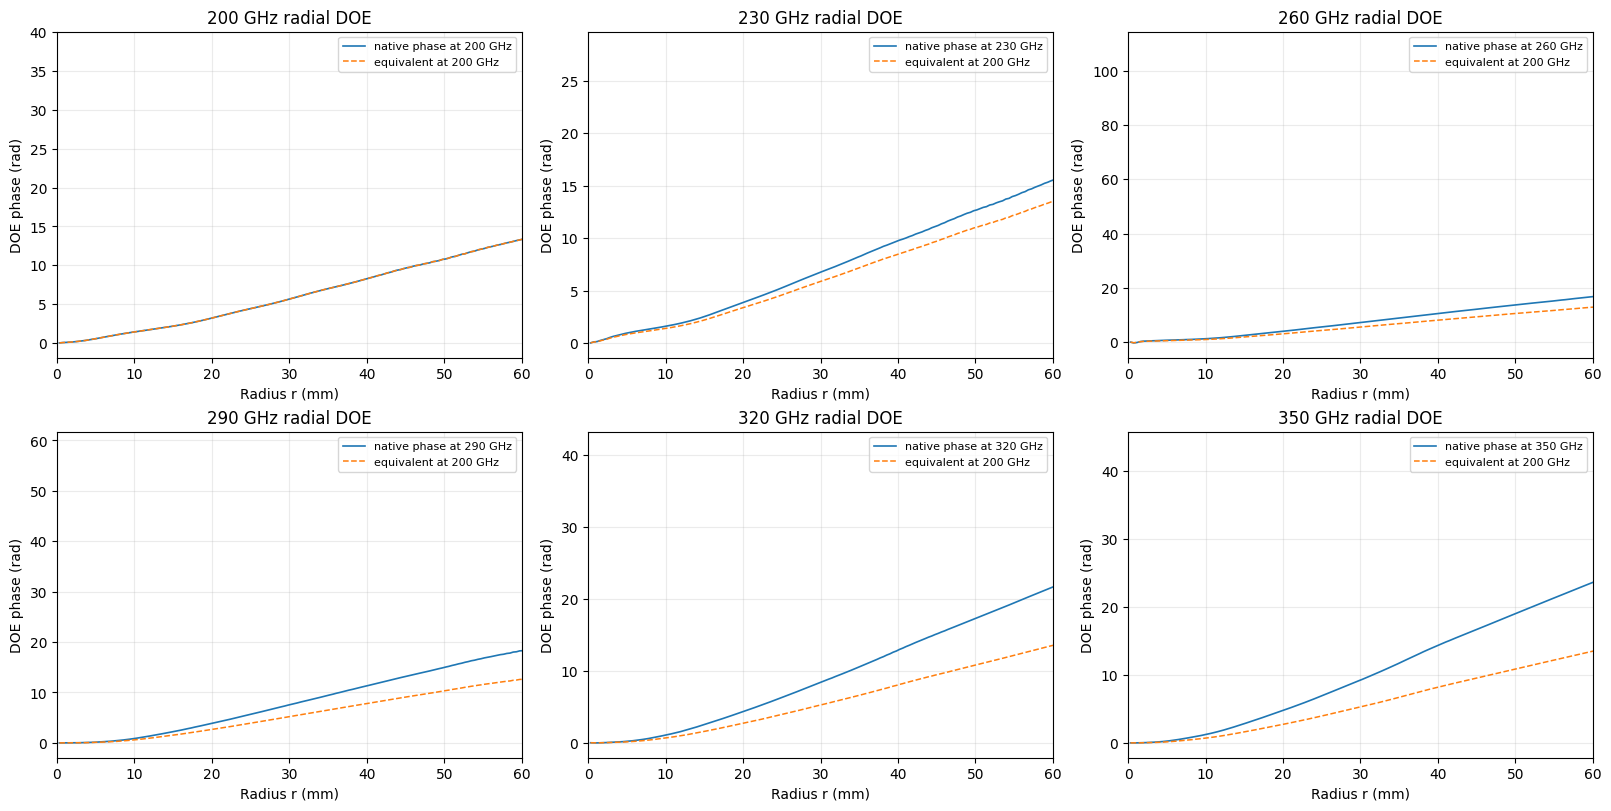

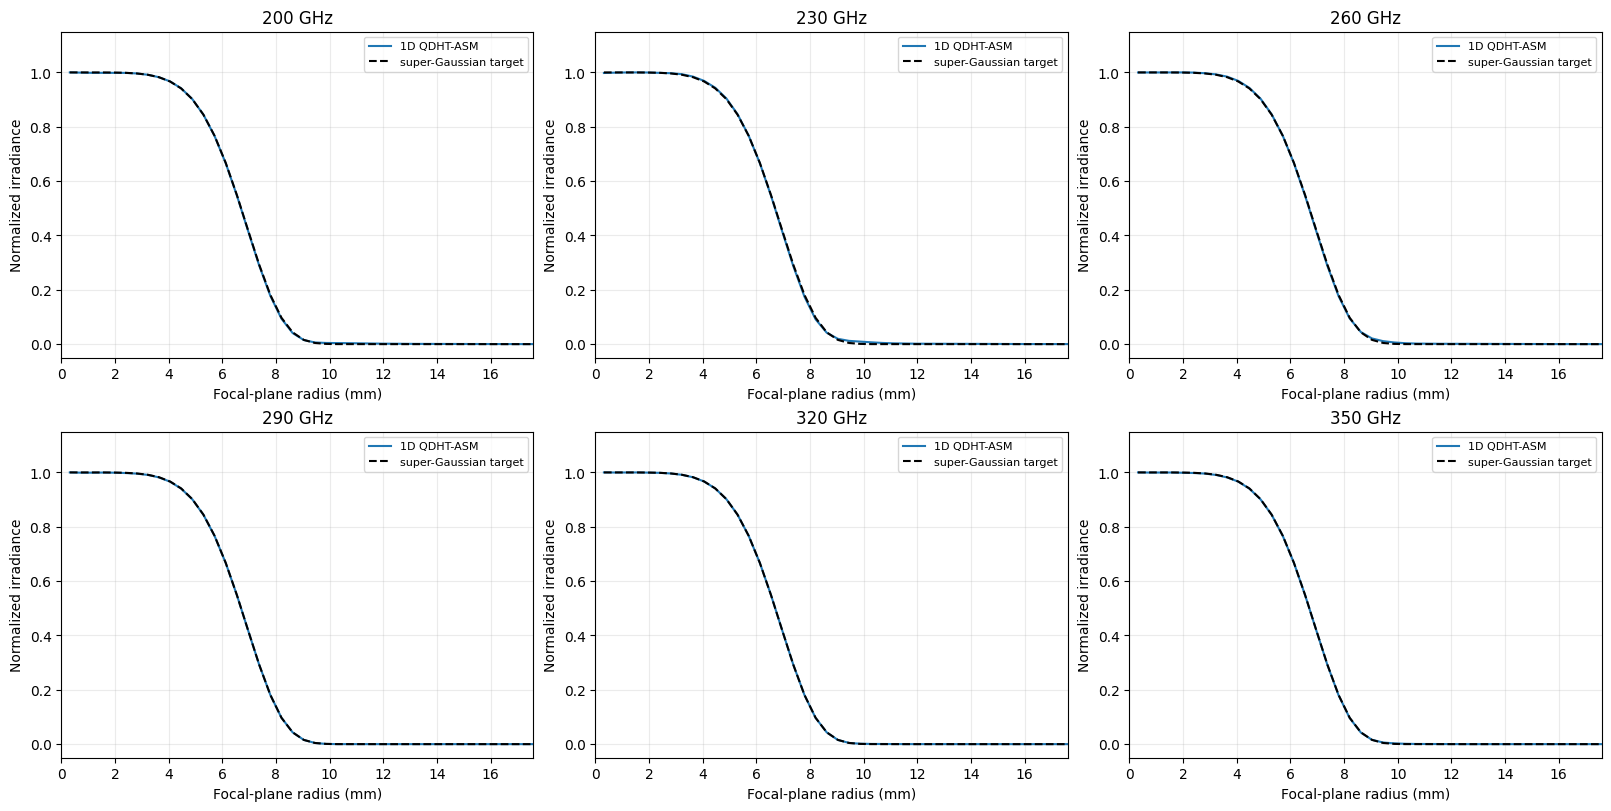

In [77]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
for ax, f_GHz in zip(axes.flat, FREQUENCIES_GHZ):
    item = one_d_designs[float(f_GHz)]
    problem = item["problem"]
    phi_native = item["phi_best"]
    phi_ref = phi_doe_reference[float(f_GHz)]

    ax.plot(problem.r, phi_native, label=f"native phase at {f_GHz:.0f} GHz", lw=1.2)
    ax.plot(problem.r, phi_ref, "--", label=f"equivalent at {F_REF_GHZ:.0f} GHz", lw=1.1)
    ax.set_xlim(0, 60)
    ax.set_xlabel("Radius r (mm)")
    ax.set_ylabel("DOE phase (rad)")
    ax.set_title(f"{f_GHz:.0f} GHz radial DOE")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
for ax, f_GHz in zip(axes.flat, FREQUENCIES_GHZ):
    item = one_d_designs[float(f_GHz)]
    problem = item["problem"]
    I = np.abs(item["metrics"]["field"])**2
    I_norm = I / (I.max() + 1e-30)
    It_norm = problem.I_t / (problem.I_t.max() + 1e-30)

    ax.plot(problem.r, I_norm, label="1D QDHT-ASM")
    ax.plot(problem.r, It_norm, "k--", label="super-Gaussian target")
    ax.set_xlim(0, 2.2 * W_TARGET_MM)
    ax.set_ylim(-0.05, 1.15)
    ax.set_xlabel("Focal-plane radius (mm)")
    ax.set_ylabel("Normalized irradiance")
    ax.set_title(f"{f_GHz:.0f} GHz")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.show()

### Optional independent Rayleigh–Sommerfeld validation

The supplied 1D notebook also includes a direct Rayleigh–Sommerfeld integral. It is retained below as an optional independent check against the QDHT-ASM result. It is computationally more expensive, so it is disabled by default.

In [78]:
RUN_RS_VALIDATION = False

if RUN_RS_VALIDATION:
    f_check = float(FREQUENCIES_GHZ[len(FREQUENCIES_GHZ)//2])
    item = one_d_designs[f_check]
    problem = item["problem"]
    rho_check = np.linspace(0.0, 14.0, 29)

    U_rs = problem.rayleigh_sommerfeld(item["phi_best"], rho_check)
    U_hankel = np.interp(rho_check, problem.r, np.abs(item["metrics"]["field"]))

    I_rs = np.abs(U_rs)**2
    I_hankel = U_hankel**2

    relative_error = np.max(np.abs(I_rs-I_hankel)) / (I_hankel.max()+1e-30)
    print(f"{f_check:.0f} GHz: RS-I vs QDHT-ASM max normalized intensity difference = {relative_error:.3e}")

    plt.figure(figsize=(8, 4))
    plt.plot(rho_check, I_rs/(I_hankel.max()+1e-30), "o", label="direct RS-I")
    plt.plot(problem.r, np.abs(item["metrics"]["field"])**2/(I_hankel.max()+1e-30), label="QDHT-ASM")
    plt.xlim(0, 14)
    plt.xlabel("Focal-plane radius (mm)")
    plt.ylabel("Intensity / QDHT peak")
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()

## 5. Convert radial profiles into 2D DOE priors

The 2D Cartesian grid is centered at the origin. A radius map is computed in physical millimetres, and each profile is interpolated using its actual QDHT radial coordinates.

The layouts are:
- **Individual radial designs:** one 2D axisymmetric DOE for each of the six 1D frequency-specific profiles.
- **Interspersed rings:** successive radial samples alternate between the six candidate profiles.
- **Permuted sectors:** the radial assignment cycles through the candidate profiles, while the azimuthal sector selects a permutation of that assignment. This follows the layout logic in the supplied 2D notebook.

These layouts are ideal phase maps. The 1440-sector option reproduces the supplied 2D notebook, but many sectors are finer than one Cartesian pixel and therefore are not fully resolved on a finite grid; reducing `N_PERMUTED_SECTORS` gives a coarser, more resolvable pattern. Very fine ring/sector transitions can generate high spatial frequencies and may require smoothing or fabrication constraints in a physical device.

2D DOE initializations:
  Radial prior 200 GHz: (575, 575), phase range [0.00, 38.16] rad
  Radial prior 230 GHz: (575, 575), phase range [0.00, 24.57] rad
  Radial prior 260 GHz: (575, 575), phase range [-0.19, 83.77] rad
  Radial prior 290 GHz: (575, 575), phase range [0.00, 40.53] rad
  Radial prior 320 GHz: (575, 575), phase range [-0.01, 25.71] rad
  Radial prior 350 GHz: (575, 575), phase range [-0.00, 24.89] rad
  Interspersed rings: (575, 575), phase range [-0.19, 75.19] rad
  Permuted sectors: (575, 575), phase range [-0.19, 83.77] rad
  Random 2D DOE (seed=2026): (575, 575), phase range [-3.14, 3.14] rad


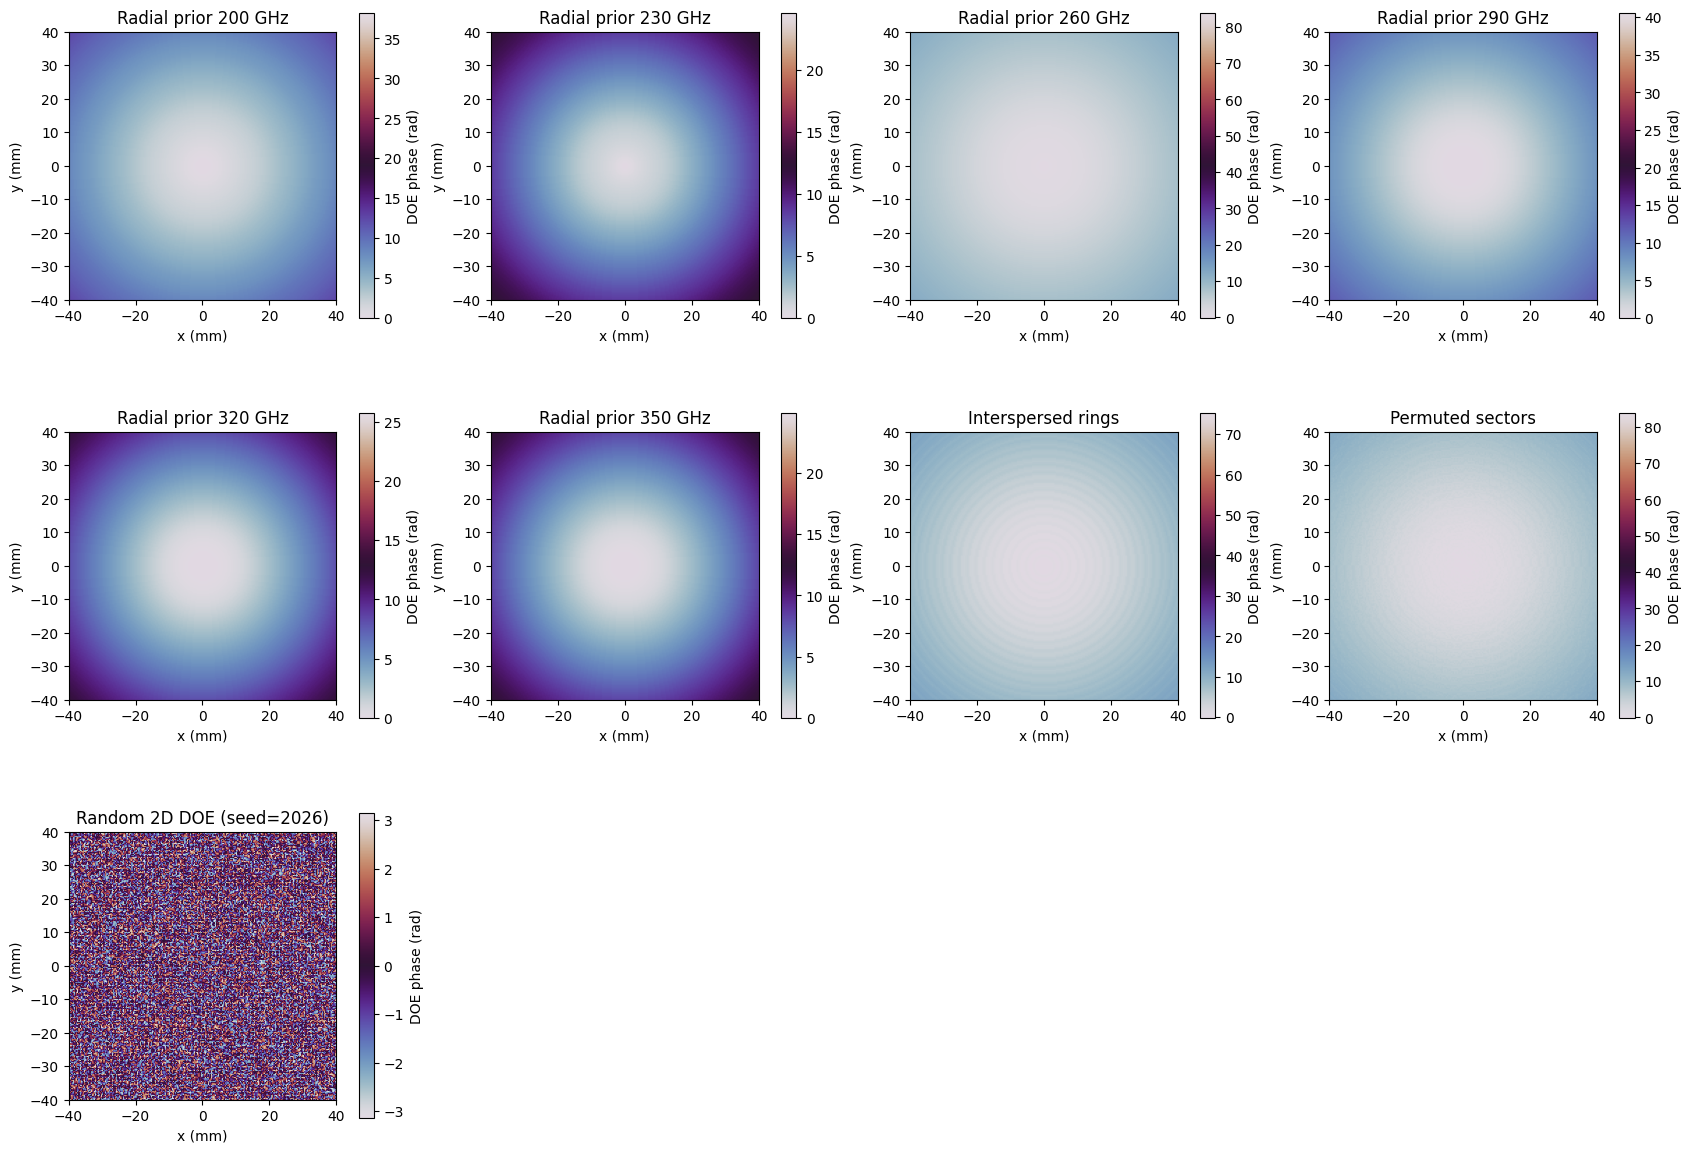

In [79]:
# Cartesian DOE-plane coordinates (mm)
coords_np = (np.arange(GRID_SHAPE) - (GRID_SHAPE - 1) / 2.0) * DX_MM
X_np, Y_np = np.meshgrid(coords_np, coords_np, indexing="xy")
R_np = np.sqrt(X_np**2 + Y_np**2)
THETA_np = np.mod(np.arctan2(Y_np, X_np), 2.0*np.pi)

# Uniform radial samples that correspond to the Cartesian pixel pitch.
r_uniform = np.arange(N_2D + 1, dtype=float) * DX_MM
r_uniform[-1] = R_MAX_MM

# Convert each native-frequency optimized DOE profile to reference-frequency phase,
# then interpolate from the nonuniform QDHT grid onto the uniform radial samples.
profile_stack = []
for f_GHz in FREQUENCIES_GHZ:
    problem = one_d_designs[float(f_GHz)]["problem"]
    phi_ref = phi_doe_reference[float(f_GHz)]
    phi_uniform = np.interp(
        r_uniform,
        problem.r,
        phi_ref,
        left=phi_ref[0],
        right=phi_ref[-1],
    )
    profile_stack.append(phi_uniform)

profile_stack = np.asarray(profile_stack, dtype=np.float32)  # (n_frequencies, N_2D+1)

# Map every Cartesian pixel to a radial sample index.
radial_index = np.rint(np.minimum(R_np, R_MAX_MM) / DX_MM).astype(int)
radial_index = np.clip(radial_index, 0, N_2D)

# Individual axisymmetric 2D lenses.
layout_phases = {}
for i, f_GHz in enumerate(FREQUENCIES_GHZ):
    layout_phases[f"Radial prior {f_GHz:.0f} GHz"] = profile_stack[i][radial_index]

# Interspersed radial rings: change the source profile from ring to ring.
ring_profile_id = radial_index % len(FREQUENCIES_GHZ)
interspersed_phase = profile_stack[ring_profile_id, radial_index]
layout_phases["Interspersed rings"] = interspersed_phase

# Permuted sectors: all permutations are used cyclically across 1440 angular sectors.
all_permutations = np.asarray(list(itertools.permutations(range(len(FREQUENCIES_GHZ)))), dtype=np.int16)
sector_index = np.floor(THETA_np / (2.0*np.pi / N_PERMUTED_SECTORS)).astype(int)
sector_index = np.clip(sector_index, 0, N_PERMUTED_SECTORS - 1)
permutation_index = sector_index % len(all_permutations)
base_profile_id = radial_index % len(FREQUENCIES_GHZ)
sector_profile_id = all_permutations[permutation_index, base_profile_id]
permuted_phase = profile_stack[sector_profile_id, radial_index]
layout_phases["Permuted sectors"] = permuted_phase

if INCLUDE_RANDOM_BASELINE:
    # Independent random phase at each Cartesian DOE pixel. A local RNG makes
    # this baseline reproducible without depending on unrelated NumPy draws.
    random_rng = np.random.default_rng(RANDOM_PHASE_SEED)
    layout_phases[RANDOM_LAYOUT_NAME] = random_rng.uniform(
        -np.pi, np.pi, size=(GRID_SHAPE, GRID_SHAPE)
    ).astype(np.float32)

layout_names = list(layout_phases.keys())
if INCLUDE_RANDOM_BASELINE and RANDOM_LAYOUT_NAME not in layout_phases:
    raise RuntimeError("The random 2D baseline was requested but was not created.")
print("2D DOE initializations:")
for name in layout_names:
    print(f"  {name}: {layout_phases[name].shape}, phase range [{layout_phases[name].min():.2f}, {layout_phases[name].max():.2f}] rad")

# Plot all initial DOE phase maps.
n_layouts = len(layout_names)
ncols = 4
nrows = int(np.ceil(n_layouts/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2*ncols, 4.0*nrows), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()
for ax, name in zip(axes, layout_names):
    im = ax.imshow(layout_phases[name], extent=[coords_np[0], coords_np[-1], coords_np[0], coords_np[-1]],
                   origin="lower", cmap="twilight")
    ax.set_title(name)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    ax.set_xlim(-40, 40)
    ax.set_ylim(-40, 40)
    fig.colorbar(im, ax=ax, shrink=0.78, label="DOE phase (rad)")
for ax in axes[len(layout_names):]:
    ax.axis("off")
plt.show()

## 6. 2D Fourier-domain angular-spectrum propagator

The 2D ASM uses
$$
H(f_x,f_y;f)=
\begin{cases}
\exp\left[i\,2\pi F\sqrt{\lambda^{-2}-f_x^2-f_y^2}\right],
& f_x^2+f_y^2\leq \lambda^{-2},\\
0,&\text{otherwise}.
\end{cases}
$$
The DOE-plane field is padded symmetrically (optionally), propagated with centered FFTs, and cropped back to the original physical window. The same ASM operator is used for forward propagation and for the adjoint/back-propagation required by the GS phase update.

The focusing lens is **not hidden in a Fourier-transform scaling factor**. It is explicitly included in the DOE-plane phase using the same exact spherical expression as in the 1D model:
$$
\phi_\mathrm{lens}(x,y;f)=-\frac{2\pi}{\lambda}
\left(\sqrt{x^2+y^2+F^2}-F\right).
$$

In [80]:
class ASM2D:
    """Batched 2D scalar angular-spectrum propagator on a centered Cartesian grid."""

    def __init__(self, frequencies_GHz, shape, dx_mm, z_mm, pad_factor=1, device=DEVICE):
        self.frequencies_GHz = np.asarray(frequencies_GHz, dtype=float)
        self.nf = len(self.frequencies_GHz)
        self.shape = int(shape)
        self.dx = float(dx_mm)
        self.z = float(z_mm)
        self.device = device

        if int(pad_factor) < 1:
            raise ValueError("pad_factor must be >= 1")
        self.pad_factor = int(pad_factor)

        # Preserve an odd grid size so the original and padded grids share the same center pixel.
        self.M = self.pad_factor * (self.shape - 1) + 1
        self.pad = (self.M - self.shape) // 2

        fx = torch_fft.fftfreq(self.M, d=self.dx, device=device, dtype=torch.float32)
        FY, FX = torch.meshgrid(fx, fx, indexing="ij")
        ftrans2 = FX**2 + FY**2

        H_list = []
        k_list = []
        for f_GHz in self.frequencies_GHz:
            wavelength = C_MM_GHZ / float(f_GHz)
            k = 2.0 * np.pi / wavelength
            kz2 = k**2 - (2.0*np.pi)**2 * ftrans2
            propagating = kz2 >= 0.0
            kz = torch.sqrt(torch.clamp(kz2, min=0.0))
            H = torch.exp(1j * kz * self.z) * propagating.to(torch.complex64)
            H_list.append(H.to(torch.complex64))
            k_list.append(k)

        self.H = torch.stack(H_list, dim=0)
        self.k = np.asarray(k_list, dtype=float)

    def _pad(self, field):
        if self.pad == 0:
            return field
        return F.pad(field, (self.pad, self.pad, self.pad, self.pad))

    def _crop(self, field):
        if self.pad == 0:
            return field
        p = self.pad
        return field[..., p:p+self.shape, p:p+self.shape]

    def forward(self, field0):
        """Forward operator C*T*P: centered input -> centered observation-plane field."""
        padded = self._pad(field0)
        spectrum = torch_fft.fft2(torch_fft.ifftshift(padded, dim=(-2, -1)), dim=(-2, -1))
        propagated = torch_fft.ifft2(spectrum * self.H, dim=(-2, -1))
        centered = torch_fft.fftshift(propagated, dim=(-2, -1))
        return self._crop(centered)

    def adjoint(self, fieldz):
        """Hermitian adjoint P^H*T^H*C^H of the cropped forward operator."""
        if self.pad == 0:
            padded = fieldz
        else:
            padded = torch.zeros(
                (fieldz.shape[0], self.M, self.M),
                dtype=torch.complex64,
                device=self.device,
            )
            p = self.pad
            padded[..., p:p+self.shape, p:p+self.shape] = fieldz

        spectrum = torch_fft.fft2(torch_fft.ifftshift(padded, dim=(-2, -1)), dim=(-2, -1))
        back = torch_fft.ifft2(spectrum * torch.conj(self.H), dim=(-2, -1))
        centered = torch_fft.fftshift(back, dim=(-2, -1))
        return self._crop(centered)


# Build the Cartesian grids and physical lens phase for every frequency.
coords_t = torch.as_tensor(coords_np, dtype=torch.float32, device=DEVICE)
Y_t, X_t = torch.meshgrid(coords_t, coords_t, indexing="ij")
R_t = torch.sqrt(X_t**2 + Y_t**2)

source_amplitude = torch.exp(-(R_t / W_IN_MM)**2)
opd_lens_mm = -(torch.sqrt(R_t**2 + FOCAL_LENGTH_MM**2) - FOCAL_LENGTH_MM)

k_values = 2.0 * np.pi / (C_MM_GHZ / FREQUENCIES_GHZ)
scales_t = torch.as_tensor(FREQUENCIES_GHZ / F_REF_GHZ, dtype=torch.float32, device=DEVICE)
k_t = torch.as_tensor(k_values, dtype=torch.float32, device=DEVICE)

lens_phase_stack = k_t[:, None, None] * opd_lens_mm[None, :, :]

asm2d = ASM2D(
    FREQUENCIES_GHZ,
    shape=GRID_SHAPE,
    dx_mm=DX_MM,
    z_mm=FOCAL_LENGTH_MM,
    pad_factor=ASM_PAD_FACTOR,
    device=DEVICE,
)

print(f"2D ASM: input/cropped grid {GRID_SHAPE}x{GRID_SHAPE}, FFT grid {asm2d.M}x{asm2d.M}")

# Numerically verify that the implemented back-propagator is the Hermitian adjoint
# of the forward operator (important for the multi-frequency GS phase update).
with torch.no_grad():
    test_x = torch.randn((len(FREQUENCIES_GHZ), GRID_SHAPE, GRID_SHAPE), dtype=torch.complex64, device=DEVICE)
    test_y = torch.randn_like(test_x)
    lhs = torch.sum(torch.conj(asm2d.forward(test_x)) * test_y)
    rhs = torch.sum(torch.conj(test_x) * asm2d.adjoint(test_y))
    adjoint_error = torch.abs(lhs-rhs) / (torch.abs(lhs)+torch.abs(rhs)+1e-12)
print(f"2D ASM adjoint relative mismatch: {float(adjoint_error.cpu()):.3e}")
if float(adjoint_error.cpu()) > 1e-4:
    raise RuntimeError("2D ASM adjoint check failed; inspect padding/FFT conventions.")


2D ASM: input/cropped grid 575x575, FFT grid 575x575
2D ASM adjoint relative mismatch: 9.901e-08


## 7. Frequency-dependent targets and loss masks

A super-Gaussian target is used, matching the 1D target:
$$
I_t(\rho)\propto \exp[-2(\rho/W_t)^{2p}],\quad p=3.
$$
The target is normalized separately at each frequency to the lens-only propagated input power, following the normalization used in the 1D notebook.

The regional loss follows the weighting scheme in the supplied 2D notebook: central region 0.65, outer target region 0.25, and background 0.10. The broadband objective also assigns 50% weight to the worst frequency and 50% to the mean frequency loss.

In [81]:
# Lens-only propagated power at each frequency (used to normalize the target).
with torch.no_grad():
    lens_only_field = source_amplitude[None, :, :].to(torch.complex64) * torch.exp(1j * lens_phase_stack)
    lens_only_output = asm2d.forward(lens_only_field)
    propagated_power = torch.sum(torch.abs(lens_only_output)**2, dim=(-2, -1)) * (DX_MM**2)

target_raw = torch.exp(-2.0 * (R_t / W_TARGET_MM)**(2 * P_EXP))
target_raw = target_raw.to(torch.float32)

target_intensities_t = []
for f_idx in range(len(FREQUENCIES_GHZ)):
    norm = propagated_power[f_idx] / (torch.sum(target_raw) * DX_MM**2 + 1e-30)
    target_intensities_t.append(target_raw * norm)

target_intensities_t = torch.stack(target_intensities_t, dim=0)
target_amplitudes_t = torch.sqrt(torch.clamp(target_intensities_t, min=0.0))

center_masks_t = (R_t[None, :, :] <= 0.5 * W_TARGET_MM).to(torch.float32).expand_as(target_intensities_t)
outer_masks_t = (
    (R_t[None, :, :] > 0.5 * W_TARGET_MM)
    & (R_t[None, :, :] <= W_TARGET_MM)
).to(torch.float32).expand_as(target_intensities_t)
background_masks_t = (R_t[None, :, :] > W_TARGET_MM).to(torch.float32).expand_as(target_intensities_t)
roi_mask_t = (R_t <= ROI_MM)

P_in_2d = torch.sum(source_amplitude**2) * DX_MM**2

print("Incident power (discrete):", float(P_in_2d.cpu()))
print("Lens-only propagated power by frequency:")
for f_GHz, power in zip(FREQUENCIES_GHZ, propagated_power):
    print(f"  {f_GHz:.0f} GHz: {float(power.cpu()):.6f}")

Incident power (discrete): 981.7477416992188
Lens-only propagated power by frequency:
  200 GHz: 981.747742
  230 GHz: 981.747742
  260 GHz: 981.747742
  290 GHz: 981.747742
  320 GHz: 981.747681
  350 GHz: 981.747742


## 8. Evaluate the unrefined 2D priors

At each frequency, the DOE phase is converted from the common reference-frequency representation using $f/f_\mathrm{ref}$, then added to the exact frequency-dependent focusing-lens phase. The 2D ASM propagates this total DOE-plane field by the focal distance.

The resulting irradiance maps and center-line profiles show whether the 1D radial prior survives the transition to a Cartesian 2D grid, and how the mixed layouts behave before 2D refinement.

In [82]:
def make_2d_input_field(phi_ref_2d):
    """DOE-only phase at f_ref -> total DOE-plane field at every frequency."""
    phi_ref_t = torch.as_tensor(phi_ref_2d, dtype=torch.float32, device=DEVICE)
    phase_doe_all_f = scales_t[:, None, None] * phi_ref_t[None, :, :]
    total_phase = phase_doe_all_f + lens_phase_stack
    return source_amplitude[None, :, :].to(torch.complex64) * torch.exp(1j * total_phase)


def evaluate_layout(phi_ref_2d):
    with torch.no_grad():
        field0 = make_2d_input_field(phi_ref_2d)
        fieldz = asm2d.forward(field0)
        intensities = torch.abs(fieldz)**2
    return intensities.detach().cpu().numpy().astype(np.float32)


def two_d_metrics(I, target_I, roi_mask=None):
    I = np.asarray(I, dtype=float)
    target_I = np.asarray(target_I, dtype=float)
    roi = (R_np <= ROI_MM) if roi_mask is None else np.asarray(roi_mask, dtype=bool)

    I_norm = I / (I.max() + 1e-30)
    target_norm = target_I / (target_I.max() + 1e-30)

    rms = np.sqrt(np.mean((I_norm[roi] - target_norm[roi])**2))

    plateau = R_np <= 0.7 * W_TARGET_MM
    ripple = (
        (I_norm[plateau].max() - I_norm[plateau].min())
        / (I_norm[plateau].max() + I_norm[plateau].min() + 1e-30)
    )

    roi_power = np.sum(I[roi]) * DX_MM**2
    efficiency = roi_power / (float(P_in_2d.cpu()) + 1e-30)
    return dict(rms=float(rms), ripple=float(ripple), roi_efficiency=float(efficiency))


pre_optimization_outputs = {}
pre_metric_rows = []

target_np = target_intensities_t.detach().cpu().numpy()

t0 = time.time()
for layout_name in layout_names:
    print("Evaluating prior:", layout_name)
    intensity_stack = evaluate_layout(layout_phases[layout_name])
    pre_optimization_outputs[layout_name] = intensity_stack

    for f_idx, f_GHz in enumerate(FREQUENCIES_GHZ):
        m = two_d_metrics(intensity_stack[f_idx], target_np[f_idx])
        pre_metric_rows.append(dict(
            stage="2D prior",
            layout=layout_name,
            frequency_GHz=float(f_GHz),
            **m,
        ))

print(f"Prior evaluation completed in {time.time()-t0:.1f} s.")
pre_metrics_df = pd.DataFrame(pre_metric_rows)
display(pre_metrics_df)

Evaluating prior: Radial prior 200 GHz
Evaluating prior: Radial prior 230 GHz
Evaluating prior: Radial prior 260 GHz
Evaluating prior: Radial prior 290 GHz
Evaluating prior: Radial prior 320 GHz
Evaluating prior: Radial prior 350 GHz
Evaluating prior: Interspersed rings
Evaluating prior: Permuted sectors
Evaluating prior: Random 2D DOE (seed=2026)
Prior evaluation completed in 1.3 s.


,stage,layout,frequency_GHz,rms,ripple,roi_efficiency
0,2D prior,Radial prior 200 GHz,200.0,0.002478,0.115436,0.997351
1,2D prior,Radial prior 200 GHz,230.0,0.049454,0.042070,0.997704
2,2D prior,Radial prior 200 GHz,260.0,0.092229,0.143036,0.997813
3,2D prior,Radial prior 200 GHz,290.0,0.129985,0.240379,0.997881
4,2D prior,Radial prior 200 GHz,320.0,0.148256,0.321630,0.997924
5,2D prior,Radial prior 200 GHz,350.0,0.161270,0.412250,0.997896
6,2D prior,Radial prior 230 GHz,200.0,0.032345,0.167657,0.996281
7,2D prior,Radial prior 230 GHz,230.0,0.004463,0.114480,0.996491
8,2D prior,Radial prior 230 GHz,260.0,0.031902,0.081153,0.996814
9,2D prior,Radial prior 230 GHz,290.0,0.059707,0.084258,0.997258


### 8.1 Compare the 1D design with its 2D radial implementation

This is a direct transfer check: for each frequency, the 1D-designed radial DOE is mapped onto the 2D grid, propagated with 2D ASM, and compared with the 1D QDHT-ASM result along a positive radial cross-section. Differences can arise from Cartesian sampling, finite-window boundaries, and the distinct discrete transform quadratures.

1D QDHT-ASM vs 2D ASM, normalized x-cut difference:


,frequency_GHz,cross_section_RMSE,maximum_absolute_difference
0,200.0,0.00163,0.00425
1,230.0,0.00137,0.00463
2,260.0,0.00214,0.00589
3,290.0,0.00269,0.00634
4,320.0,0.00377,0.00856
5,350.0,0.00421,0.01053


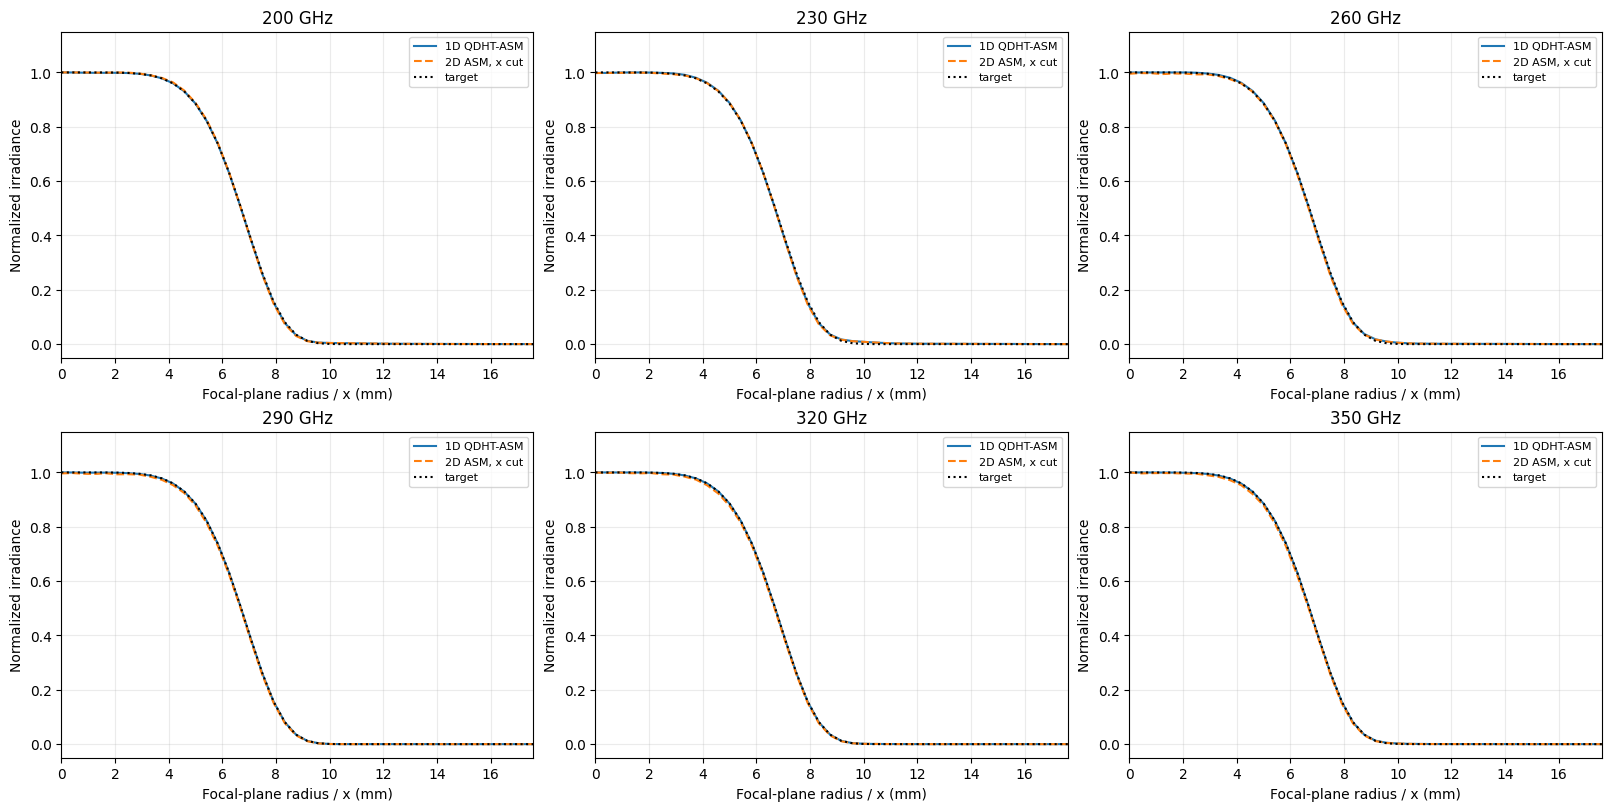

In [83]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)

center = GRID_SHAPE // 2
x_positive = coords_np[center:]

# Quantify the radial 1D -> Cartesian 2D transfer error inside the plotted region.
validation_rows = []
for f_GHz in FREQUENCIES_GHZ:
    f_GHz = float(f_GHz)
    item = one_d_designs[f_GHz]
    problem = item["problem"]
    layout_name = f"Radial prior {f_GHz:.0f} GHz"
    f_idx = int(np.where(FREQUENCIES_GHZ == f_GHz)[0][0])
    I2d = pre_optimization_outputs[layout_name][f_idx]
    line_2d = I2d[center, center:]
    line_2d = line_2d / (line_2d.max() + 1e-30)

    I1d = np.abs(item["metrics"]["field"])**2
    line_1d = np.interp(x_positive, problem.r, I1d / (I1d.max() + 1e-30))
    check_region = x_positive <= 2.2 * W_TARGET_MM
    difference = line_2d[check_region] - line_1d[check_region]

    validation_rows.append(dict(
        frequency_GHz=f_GHz,
        cross_section_RMSE=float(np.sqrt(np.mean(difference**2))),
        maximum_absolute_difference=float(np.max(np.abs(difference))),
    ))

print("1D QDHT-ASM vs 2D ASM, normalized x-cut difference:")
display(pd.DataFrame(validation_rows).round(5))

for ax, f_GHz in zip(axes.flat, FREQUENCIES_GHZ):
    f_GHz = float(f_GHz)
    item = one_d_designs[f_GHz]
    problem = item["problem"]

    layout_name = f"Radial prior {f_GHz:.0f} GHz"
    f_idx = int(np.where(FREQUENCIES_GHZ == f_GHz)[0][0])
    I2d = pre_optimization_outputs[layout_name][f_idx]
    I2d_norm = I2d / (I2d.max() + 1e-30)
    line_2d = I2d_norm[center, center:]

    I1d = np.abs(item["metrics"]["field"])**2
    I1d_norm = I1d / (I1d.max() + 1e-30)
    line_1d = np.interp(x_positive, problem.r, I1d_norm)

    target_1d = problem.I_t / (problem.I_t.max() + 1e-30)
    target_line = np.interp(x_positive, problem.r, target_1d)

    ax.plot(x_positive, line_1d, label="1D QDHT-ASM")
    ax.plot(x_positive, line_2d, "--", label="2D ASM, x cut")
    ax.plot(x_positive, target_line, "k:", label="target")
    ax.set_xlim(0, 2.2*W_TARGET_MM)
    ax.set_ylim(-0.05, 1.15)
    ax.set_title(f"{f_GHz:.0f} GHz")
    ax.set_xlabel("Focal-plane radius / x (mm)")
    ax.set_ylabel("Normalized irradiance")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.show()

### 8.2 Unrefined 2D irradiance maps and cross-sections

Each layout is shown separately. The six panels in each map figure correspond to the six frequencies. Intensities are normalized to their own peak to compare the flat-top shape; the metric table above separately reports power efficiency.

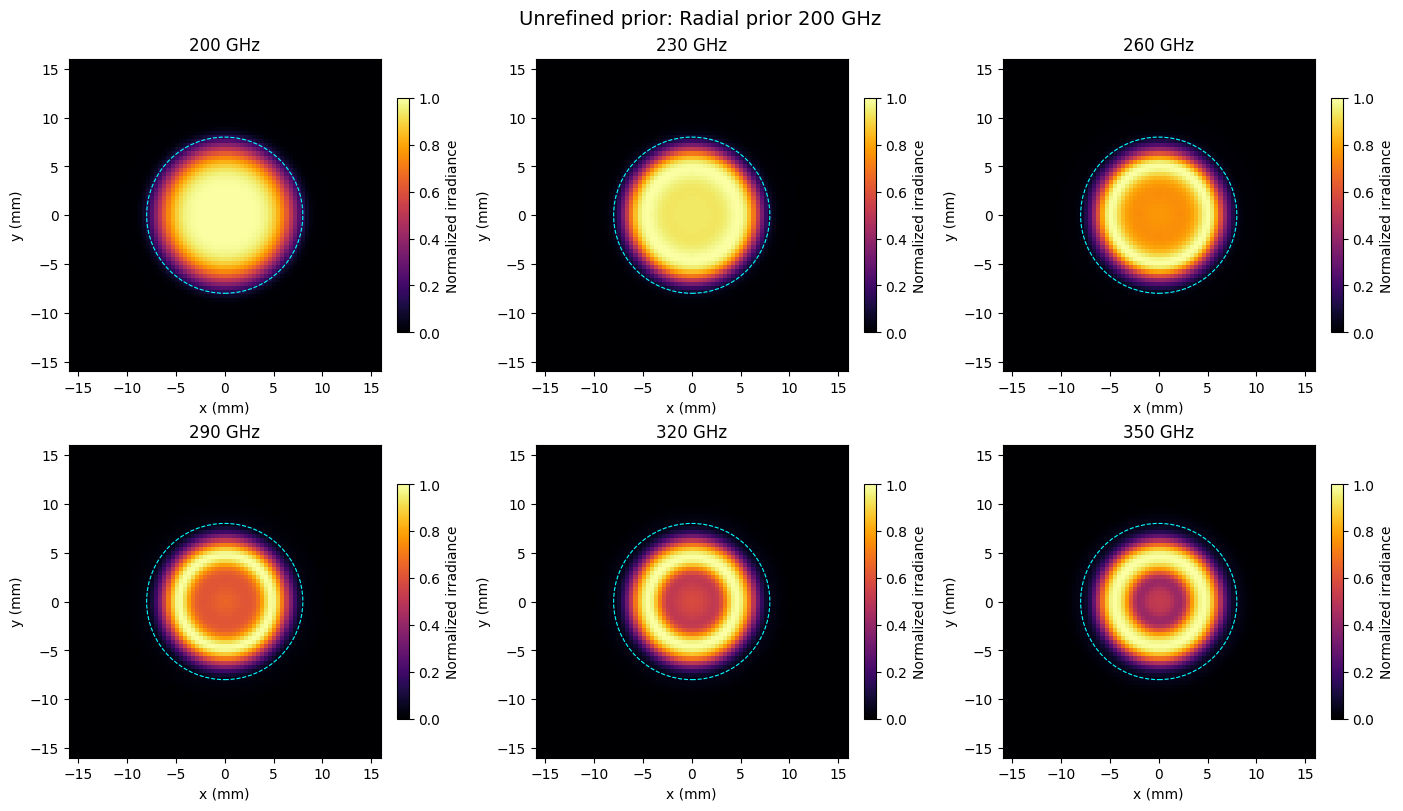

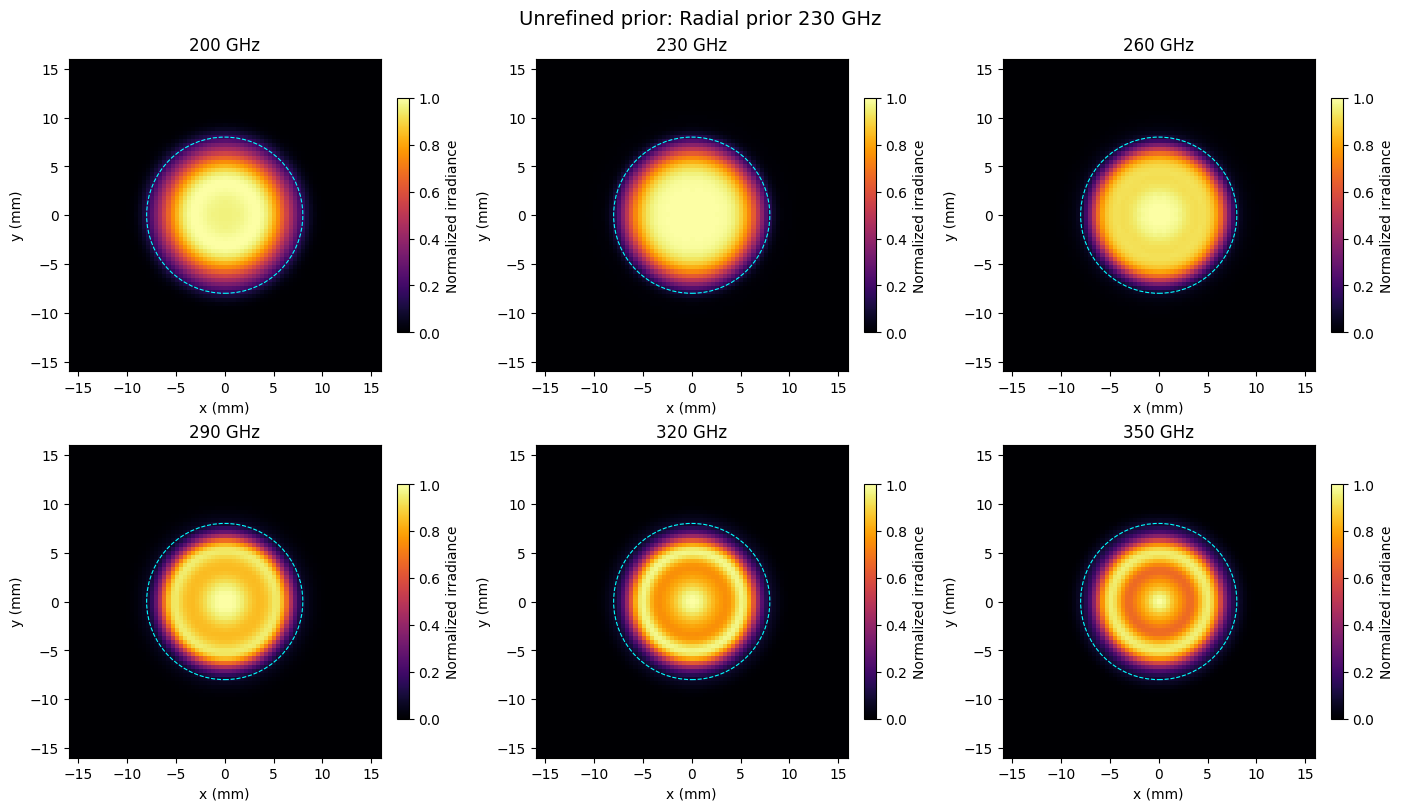

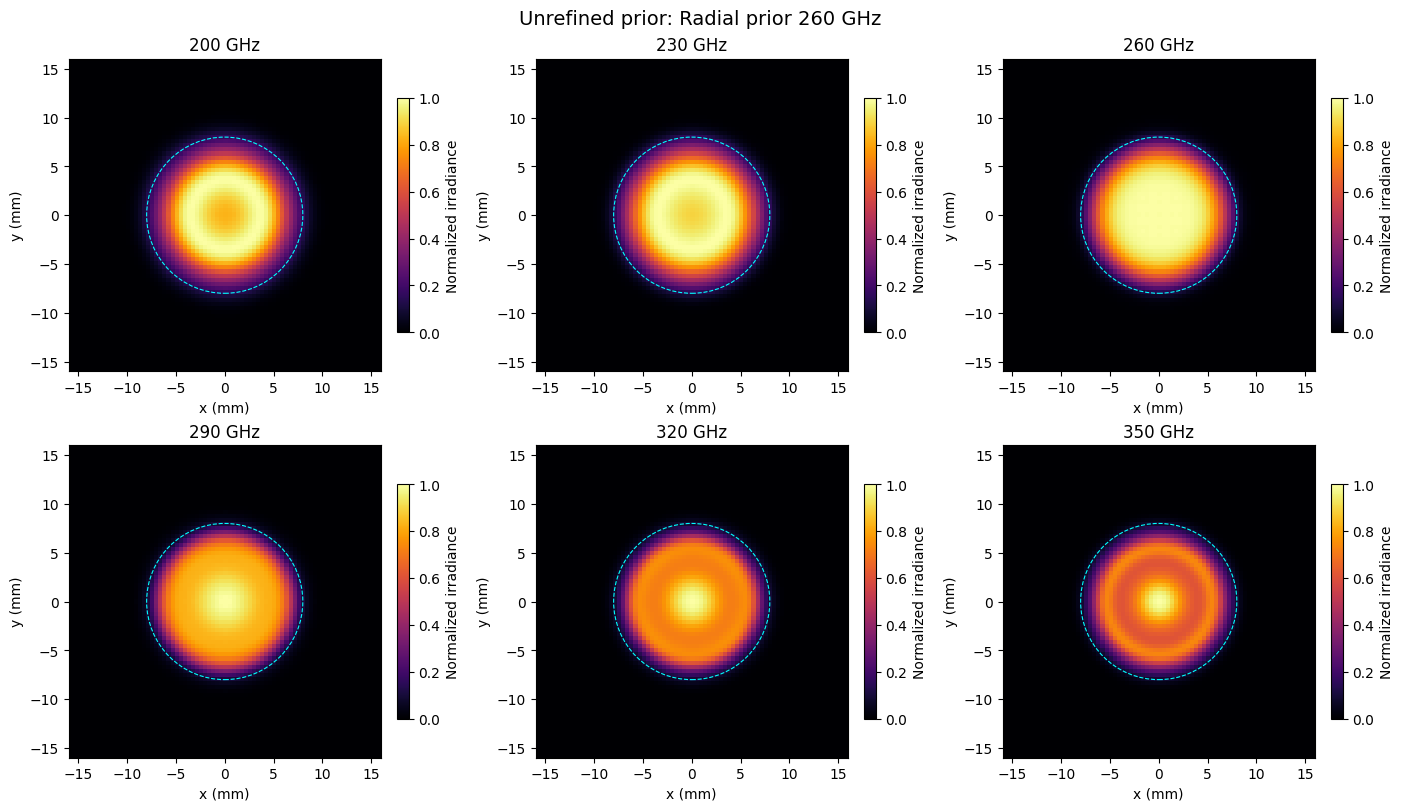

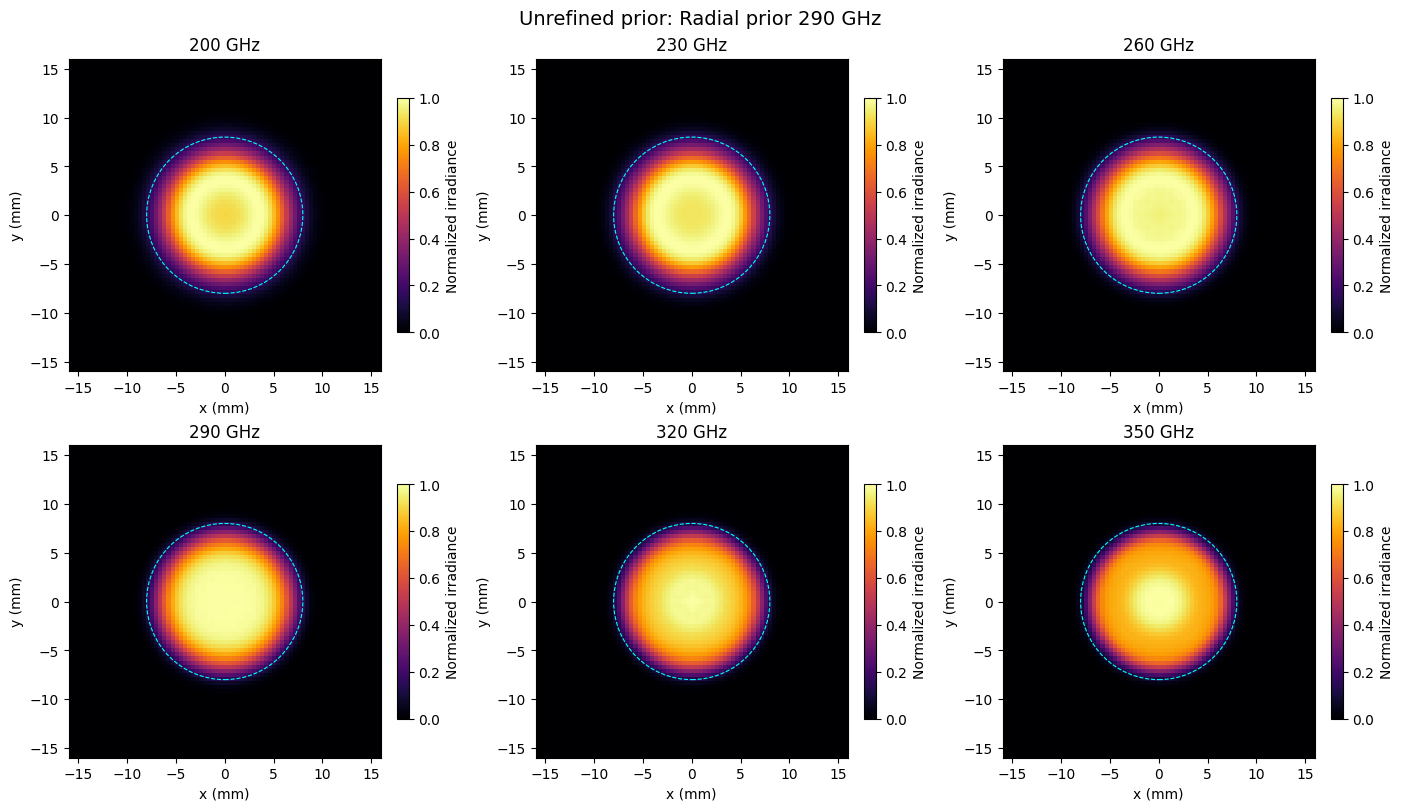

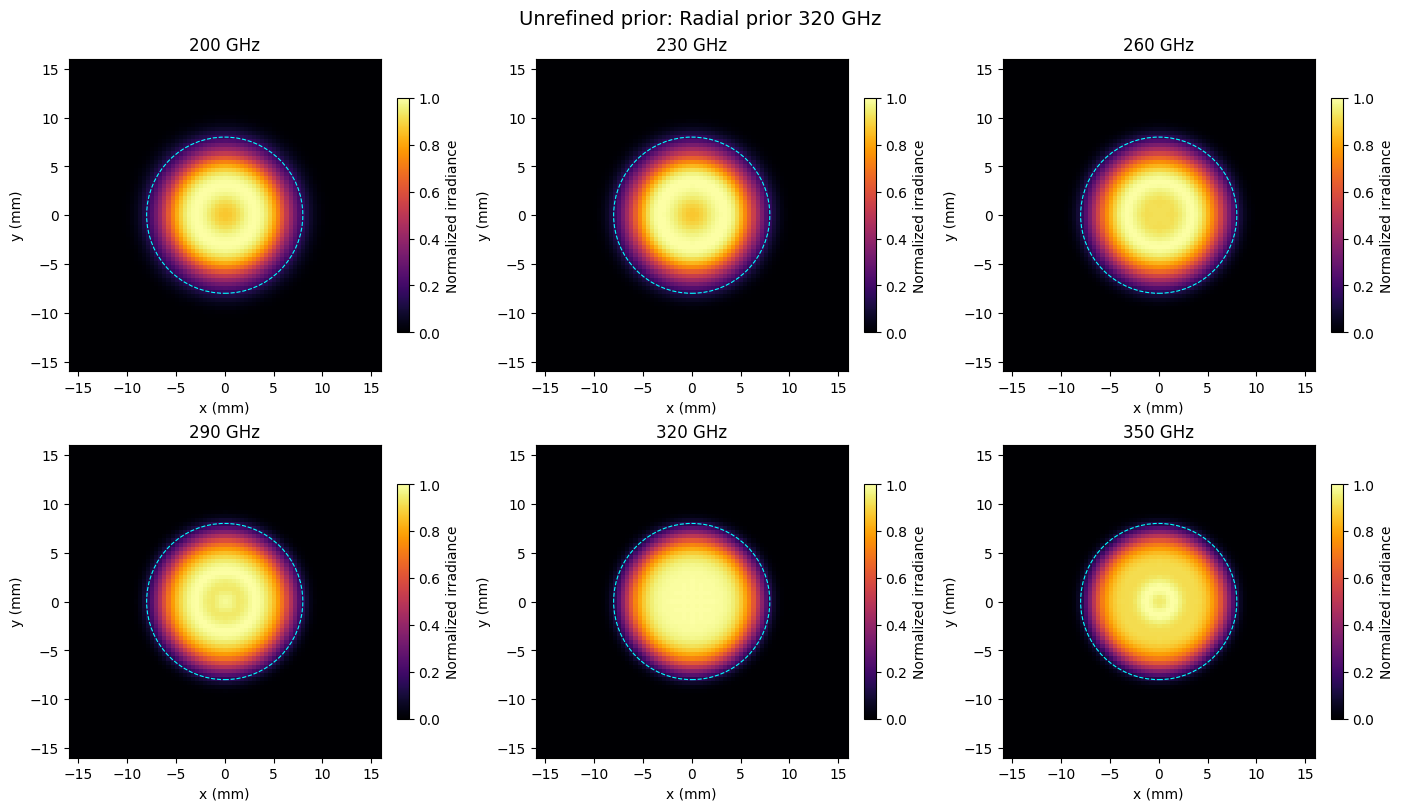

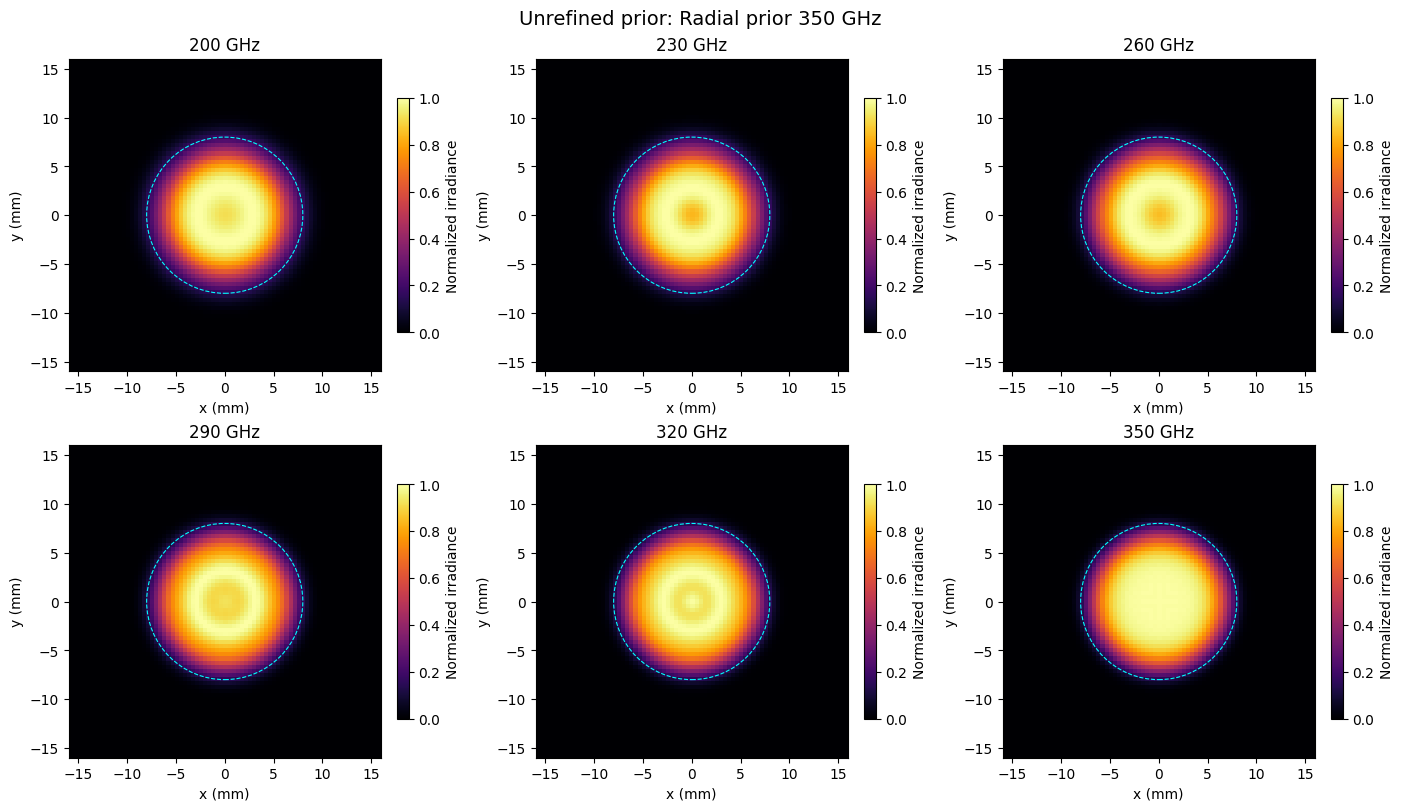

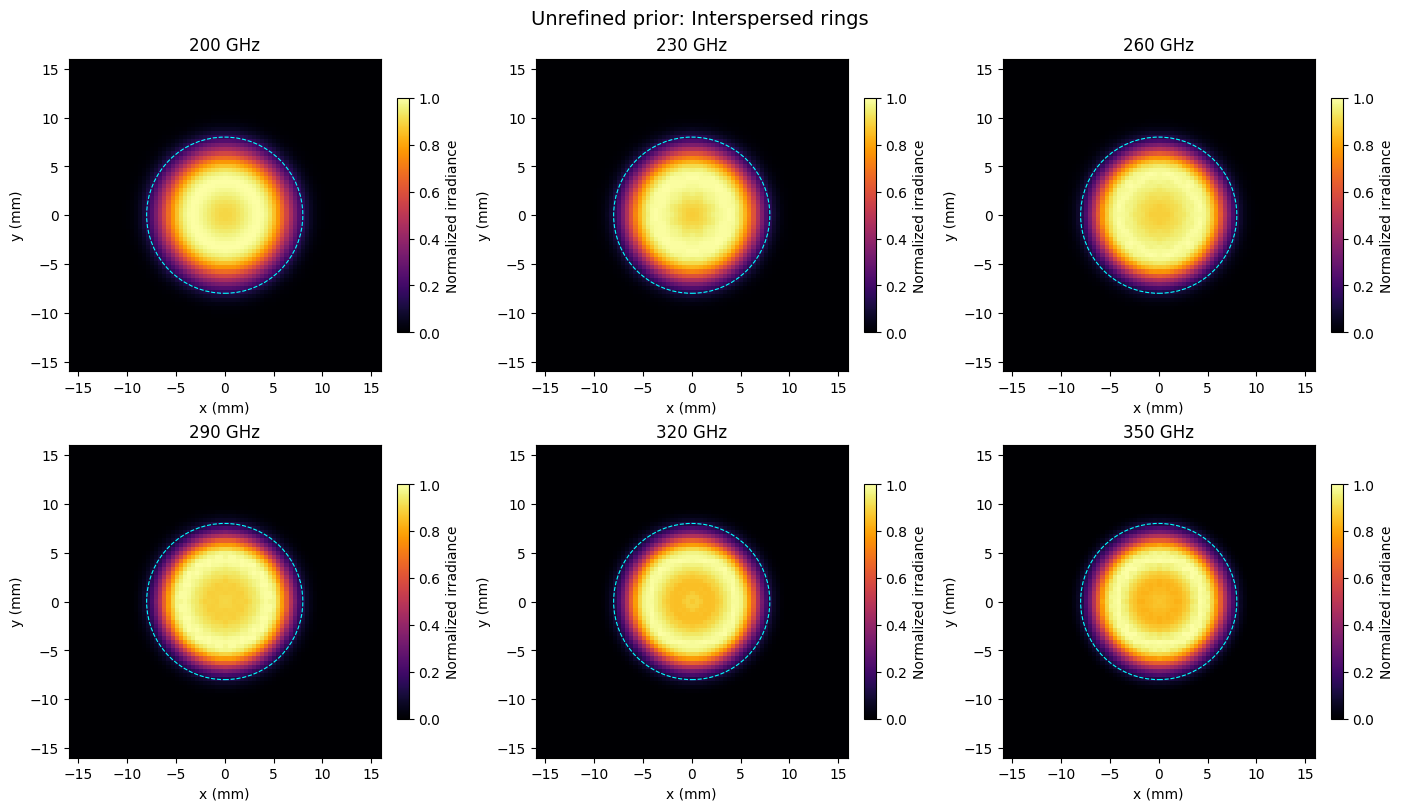

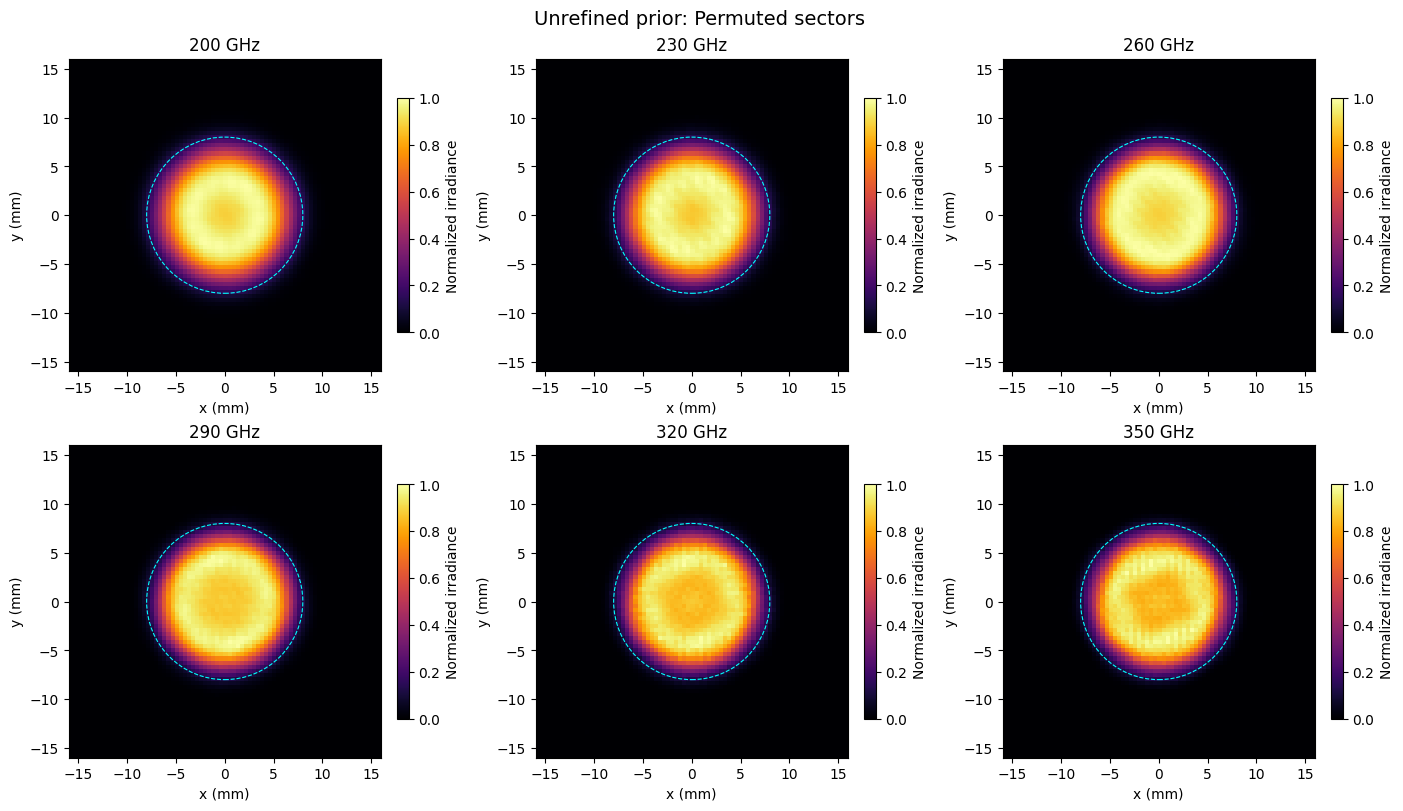

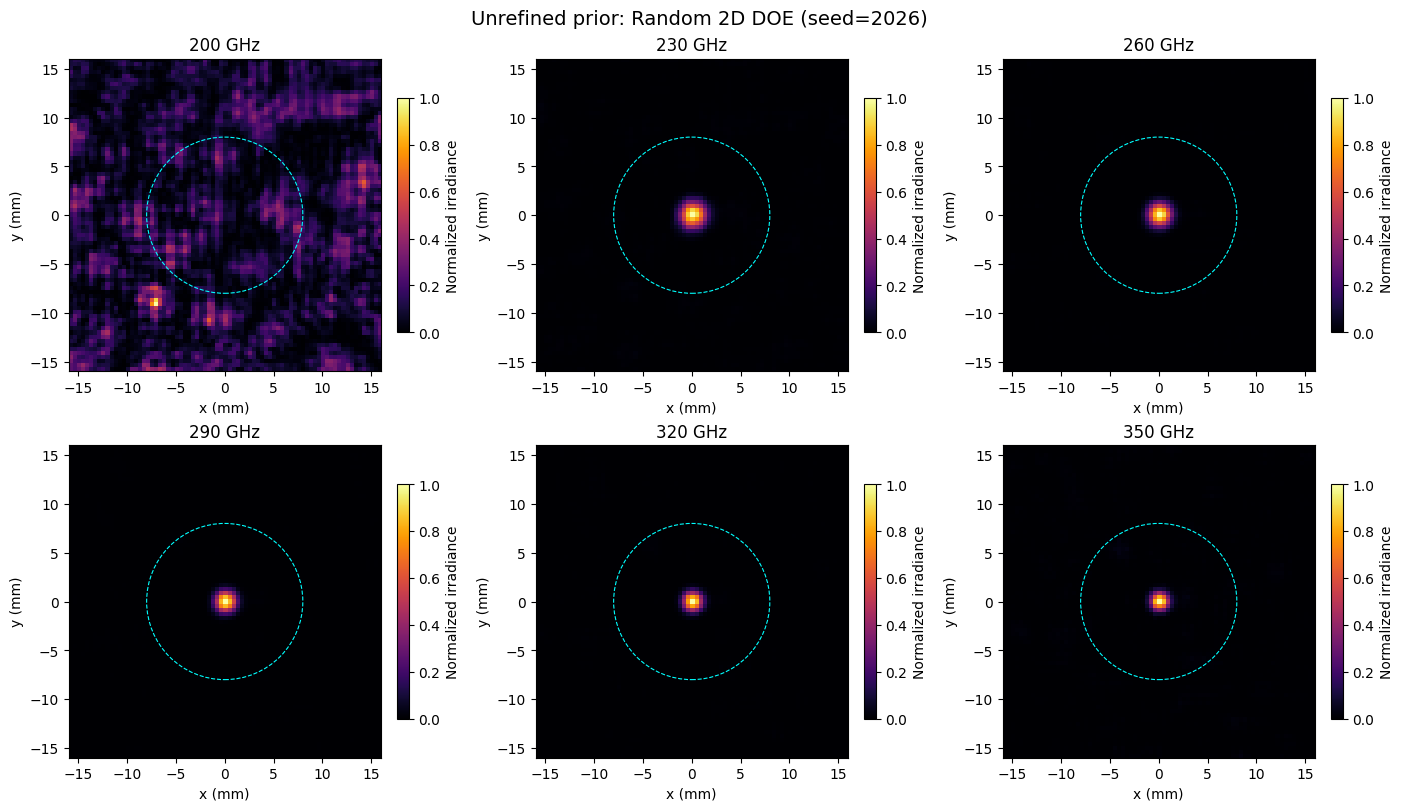

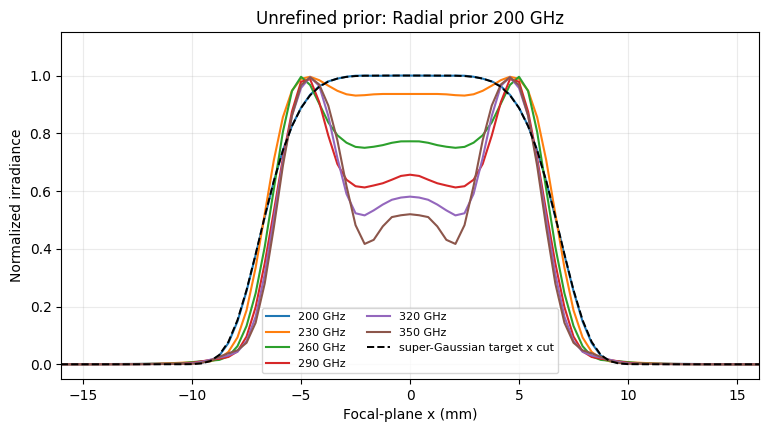

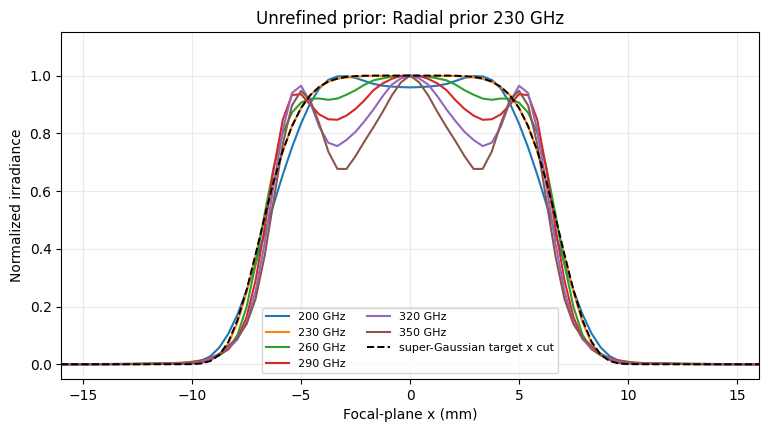

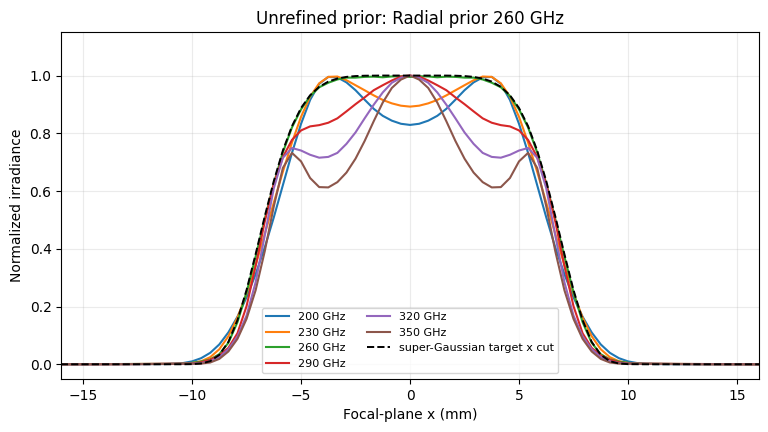

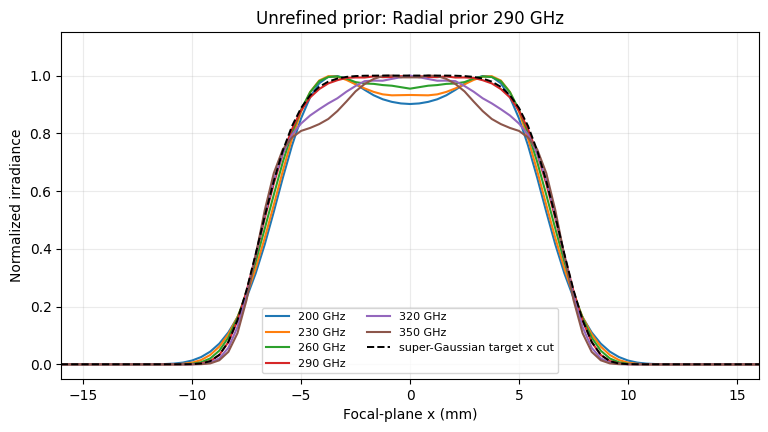

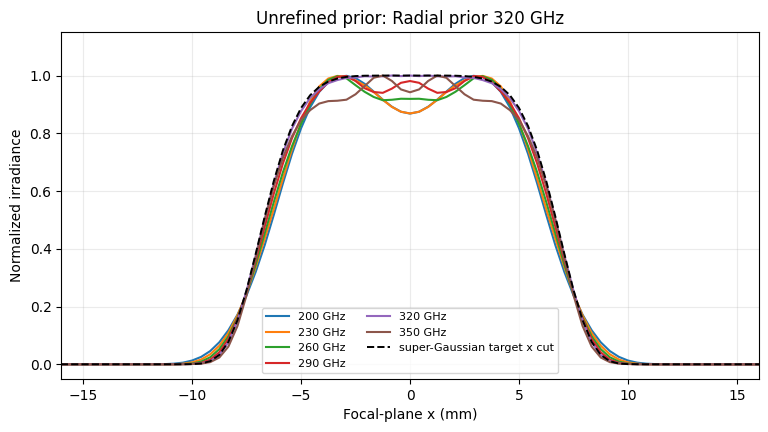

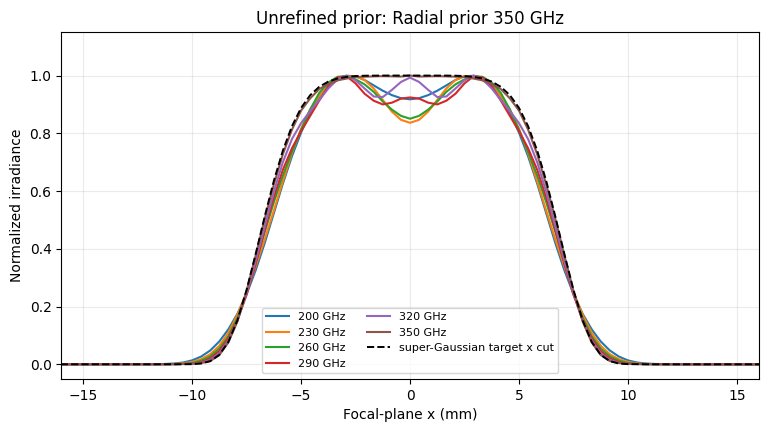

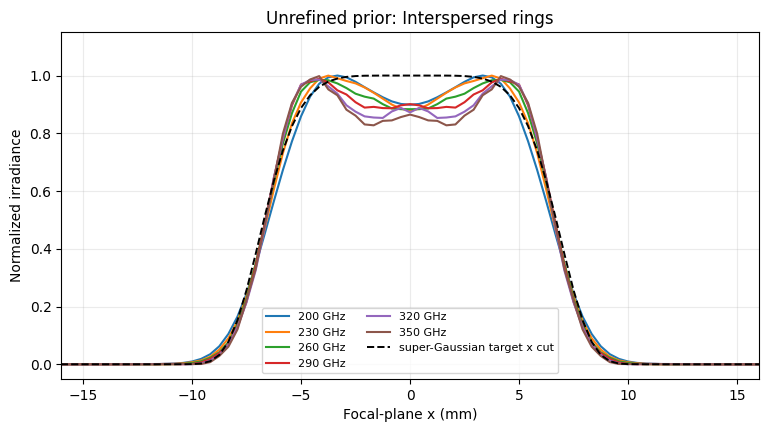

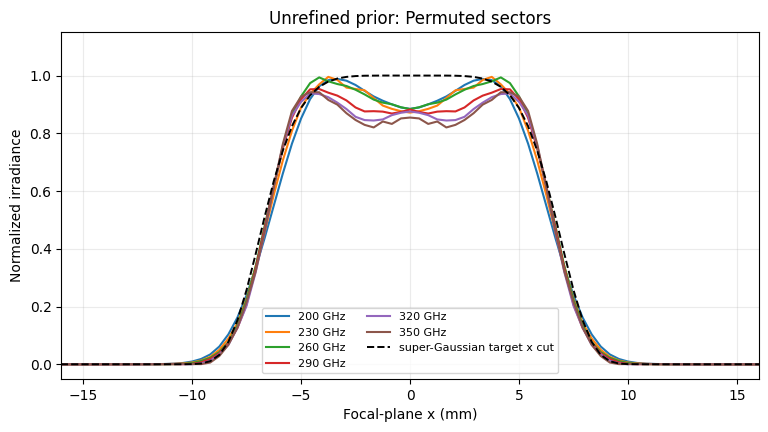

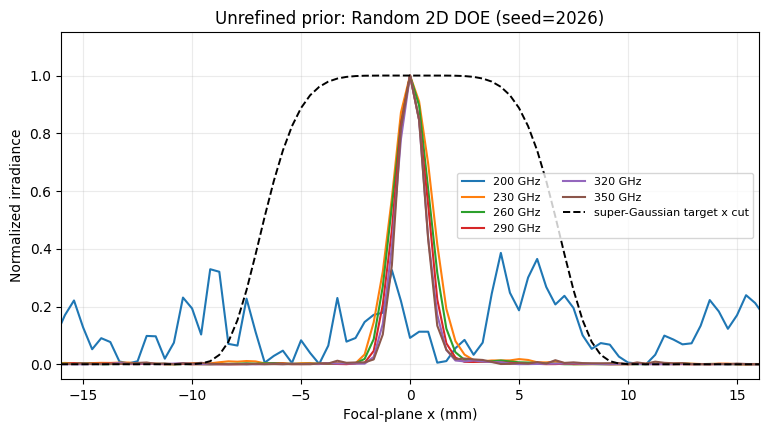

In [84]:
def plot_frequency_maps(output_dict, stage_title, names=None):
    names = list(output_dict.keys()) if names is None else list(names)
    extent = [coords_np[0], coords_np[-1], coords_np[0], coords_np[-1]]
    crop = 2.0 * W_TARGET_MM

    for layout_name in names:
        I_stack = output_dict[layout_name]
        fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
        for f_idx, (ax, f_GHz) in enumerate(zip(axes.flat, FREQUENCIES_GHZ)):
            I = I_stack[f_idx]
            I_norm = I / (I.max() + 1e-30)
            im = ax.imshow(
                I_norm,
                extent=extent,
                origin="lower",
                cmap="inferno",
                vmin=0.0,
                vmax=1.0,
            )
            ax.set_xlim(-crop, crop)
            ax.set_ylim(-crop, crop)
            ax.set_aspect("equal")
            ax.set_title(f"{f_GHz:.0f} GHz")
            ax.set_xlabel("x (mm)")
            ax.set_ylabel("y (mm)")
            ax.add_patch(plt.Circle((0, 0), W_TARGET_MM, fill=False, color="cyan", ls="--", lw=0.8))
            fig.colorbar(im, ax=ax, shrink=0.75, label="Normalized irradiance")
        fig.suptitle(f"{stage_title}: {layout_name}", fontsize=14)
        plt.show()


def plot_frequency_cross_sections(output_dict, stage_title, names=None):
    names = list(output_dict.keys()) if names is None else list(names)
    center = GRID_SHAPE // 2
    crop = 2.0 * W_TARGET_MM

    for layout_name in names:
        fig, ax = plt.subplots(figsize=(9, 4.5))
        for f_idx, f_GHz in enumerate(FREQUENCIES_GHZ):
            I = output_dict[layout_name][f_idx]
            I_norm = I / (I.max() + 1e-30)
            ax.plot(coords_np, I_norm[center, :], label=f"{f_GHz:.0f} GHz")
        target_x = np.exp(-2.0 * (np.abs(coords_np) / W_TARGET_MM)**(2 * P_EXP))
        target_x = target_x / (target_x.max() + 1e-30)
        ax.plot(
            coords_np,
            target_x,
            "k--",
            lw=1.4,
            label="super-Gaussian target x cut",
        )
        ax.set_xlim(-crop, crop)
        ax.set_ylim(-0.05, 1.15)
        ax.set_xlabel("Focal-plane x (mm)")
        ax.set_ylabel("Normalized irradiance")
        ax.set_title(f"{stage_title}: {layout_name}")
        ax.grid(alpha=0.25)
        ax.legend(ncol=2, fontsize=8)
        plt.show()


plot_frequency_maps(pre_optimization_outputs, "Unrefined prior")
plot_frequency_cross_sections(pre_optimization_outputs, "Unrefined prior")

## 9. Broadband 2D phase-only refinement

### 9.1 Multi-frequency Gerchberg–Saxton update

The 2D prior phase is a single physical DOE phase at $f_\mathrm{ref}$. At every iteration and frequency:

1. Add the frequency-scaled DOE phase and the exact focusing-lens phase.
2. Propagate to the focal plane with 2D ASM.
3. Replace the output amplitude inside the target ROI by the normalized super-Gaussian target amplitude, preserving the propagated phase; set the field to zero outside the ROI.
4. Back-propagate with the Hermitian adjoint ASM.
5. Estimate a correction to the common reference-frequency DOE phase.

Because all frequencies share one physical DOE, their phase corrections cannot be applied independently. The update below finds a least-squares common correction across frequencies:
$$
\Delta\phi_\mathrm{ref}
=\frac{\sum_i w_i s_i\,\Delta\theta_i}
       {\sum_i w_i s_i^2},\qquad s_i=f_i/f_\mathrm{ref},
$$
where $\Delta\theta_i$ is the wrapped phase correction returned at frequency $f_i$. A relaxation factor damps the common update.

### 9.2 Optional Adam polish

The supplied `wideband_continuous_phase_v2` uses a shared 2D phase parameter and minimizes a regional, worst-frequency-weighted loss with Adam. That is not classical GS. The optional Adam cell below preserves that actual optimizer as a polish stage after the GS iteration.

In [85]:
def regional_loss_torch(I_out, I_target):
    intensity_scale = torch.max(I_target)
    normalized_error = ((I_out - I_target) / (intensity_scale + 1e-12))**2

    eps = 1e-12
    loss_center = torch.sum(center_masks_t * normalized_error, dim=(-2, -1)) / (
        torch.sum(center_masks_t, dim=(-2, -1)) + eps
    )
    loss_outer = torch.sum(outer_masks_t * normalized_error, dim=(-2, -1)) / (
        torch.sum(outer_masks_t, dim=(-2, -1)) + eps
    )
    loss_background = torch.sum(background_masks_t * normalized_error, dim=(-2, -1)) / (
        torch.sum(background_masks_t, dim=(-2, -1)) + eps
    )

    return (
        W_CENTER * loss_center
        + W_OUTER * loss_outer
        + W_BACKGROUND * loss_background
    )


def broadband_loss_from_intensity(I_stack):
    per_frequency_losses = regional_loss_torch(I_stack, target_intensities_t)
    mean_loss = torch.mean(per_frequency_losses)
    worst_loss = torch.max(per_frequency_losses)
    total_loss = (1.0 - W_WORST_FREQUENCY) * mean_loss + W_WORST_FREQUENCY * worst_loss
    return total_loss, per_frequency_losses


def run_multifrequency_gs(phi_ref_initial, n_iter=GS_2D_ITERATIONS, relaxation=GS_2D_RELAXATION):
    """Generalized multi-frequency phase-only GS for one shared physical DOE."""
    phi_ref = torch.as_tensor(phi_ref_initial, dtype=torch.float32, device=DEVICE).clone()
    history = []

    amp = source_amplitude[None, :, :].expand(len(FREQUENCIES_GHZ), -1, -1)
    source_support = amp > 1e-5
    scales = scales_t[:, None, None]

    for it in range(int(n_iter)):
        phi_all = scales * phi_ref[None, :, :] + lens_phase_stack
        U0 = amp.to(torch.complex64) * torch.exp(1j * phi_all)
        Uz = asm2d.forward(U0)

        intensity = torch.abs(Uz)**2
        loss, per_f_loss = broadband_loss_from_intensity(intensity)
        history.append(per_f_loss.detach().cpu().numpy())

        # Amplitude projection at each frequency, preserving the current output phase.
        U_projected = target_amplitudes_t * torch.exp(1j * torch.angle(Uz))
        U_projected = torch.where(
            roi_mask_t[None, :, :],
            U_projected,
            torch.zeros_like(U_projected),
        )

        U_back = asm2d.adjoint(U_projected)
        delta_theta = torch.angle(U_back * torch.conj(U0))

        # Least-squares update for one shared reference-frequency phase.
        weights = torch.ones_like(scales)
        numerator = torch.sum(weights * scales * delta_theta, dim=0)
        denominator = torch.sum(weights * scales**2, dim=0) + 1e-12
        delta_phi_ref = numerator / denominator

        phi_ref = torch.where(
            source_support[0],
            phi_ref + float(relaxation) * delta_phi_ref,
            phi_ref,
        )

        if (it + 1) % 10 == 0 or it == 0:
            print(
                f"GS {it+1:4d}/{n_iter}: "
                f"mean loss={per_f_loss.mean().item():.4e}, "
                f"worst loss={per_f_loss.max().item():.4e}"
            )

    return phi_ref.detach().cpu().numpy(), np.asarray(history)


def run_multifrequency_adam(phi_ref_initial, n_iter=ADAM_2D_ITERATIONS, learning_rate=ADAM_LEARNING_RATE):
    """Optional differentiable multi-frequency Adam refinement, matching the supplied 2D notebook."""
    phi = torch.nn.Parameter(
        torch.as_tensor(phi_ref_initial, dtype=torch.float32, device=DEVICE).clone()
    )
    optimizer = torch.optim.Adam([phi], lr=float(learning_rate))
    history = []

    for it in range(int(n_iter)):
        optimizer.zero_grad()

        phi_all = scales_t[:, None, None] * phi[None, :, :] + lens_phase_stack
        U0 = source_amplitude[None, :, :].to(torch.complex64) * torch.exp(1j * phi_all)
        Uz = asm2d.forward(U0)
        I_stack = torch.abs(Uz)**2

        loss, per_f_loss = broadband_loss_from_intensity(I_stack)
        loss.backward()
        optimizer.step()

        history.append(per_f_loss.detach().cpu().numpy())

        if (it + 1) % 20 == 0 or it == 0:
            print(
                f"Adam {it+1:4d}/{n_iter}: "
                f"mean loss={per_f_loss.mean().item():.4e}, "
                f"worst loss={per_f_loss.max().item():.4e}"
            )

    return phi.detach().cpu().numpy(), np.asarray(history)

## 10. Refine each 2D prior and evaluate the final lenses

Every initialization is refined independently: the six 1D radial starts, both mixed layouts, and the random Cartesian DOE. Each run optimizes one shared physical DOE phase across all six frequencies, using the same GS iteration count, relaxation, loss, ASM propagator, and optional Adam polish. The focusing lens remains fixed and explicit throughout the optimization. This makes the random DOE a direct initialization baseline rather than a separately tuned case.

In [86]:
optimized_phases = {}
gs_histories = {}
adam_histories = {}
optimized_outputs = {}
post_metric_rows = []

t0 = time.time()

for layout_name in layout_names:
    print(f"\n========== Refining: {layout_name} ==========")

    phi_gs, gs_history = run_multifrequency_gs(
        layout_phases[layout_name],
        n_iter=GS_2D_ITERATIONS,
        relaxation=GS_2D_RELAXATION,
    )
    gs_histories[layout_name] = gs_history

    phi_final = phi_gs
    if RUN_ADAM_POLISH:
        print("Starting optional Adam polish...")
        phi_final, adam_history = run_multifrequency_adam(
            phi_gs,
            n_iter=ADAM_2D_ITERATIONS,
            learning_rate=ADAM_LEARNING_RATE,
        )
        adam_histories[layout_name] = adam_history

    optimized_phases[layout_name] = phi_final
    final_I_stack = evaluate_layout(phi_final)
    optimized_outputs[layout_name] = final_I_stack

    for f_idx, f_GHz in enumerate(FREQUENCIES_GHZ):
        m = two_d_metrics(final_I_stack[f_idx], target_np[f_idx])
        post_metric_rows.append(dict(
            stage="2D refined" if not RUN_ADAM_POLISH else "2D GS + Adam",
            layout=layout_name,
            frequency_GHz=float(f_GHz),
            **m,
        ))

print(f"\nAll 2D refinements completed in {time.time()-t0:.1f} s.")
post_metrics_df = pd.DataFrame(post_metric_rows)
display(post_metrics_df)


========== Refining: Radial prior 200 GHz ==========
GS    1/25: mean loss=2.7959e-02, worst loss=7.0272e-02
GS   10/25: mean loss=2.0520e-03, worst loss=4.9371e-03
GS   20/25: mean loss=7.5083e-04, worst loss=1.2697e-03

========== Refining: Radial prior 230 GHz ==========
GS    1/25: mean loss=6.4330e-03, worst loss=1.8053e-02
GS   10/25: mean loss=7.7478e-04, worst loss=1.4787e-03
GS   20/25: mean loss=6.4128e-04, worst loss=1.0874e-03

========== Refining: Radial prior 260 GHz ==========
GS    1/25: mean loss=5.1354e-03, worst loss=1.6364e-02
GS   10/25: mean loss=1.1577e-03, worst loss=2.4396e-03
GS   20/25: mean loss=7.1405e-04, worst loss=1.3377e-03

========== Refining: Radial prior 290 GHz ==========
GS    1/25: mean loss=1.0416e-03, worst loss=2.3543e-03
GS   10/25: mean loss=7.4124e-04, worst loss=1.5116e-03
GS   20/25: mean loss=7.2636e-04, worst loss=1.2572e-03

========== Refining: Radial prior 320 GHz ==========
GS    1/25: mean loss=1.0116e-03, worst loss=2.0826e-03
GS

,stage,layout,frequency_GHz,rms,ripple,roi_efficiency
0,2D refined,Radial prior 200 GHz,200.0,0.037041,0.167544,0.999982
1,2D refined,Radial prior 200 GHz,230.0,0.023950,0.138489,0.999998
2,2D refined,Radial prior 200 GHz,260.0,0.017927,0.115117,0.999999
3,2D refined,Radial prior 200 GHz,290.0,0.019208,0.097610,1.000000
4,2D refined,Radial prior 200 GHz,320.0,0.023381,0.084789,1.000000
5,2D refined,Radial prior 200 GHz,350.0,0.028000,0.074780,1.000000
6,2D refined,Radial prior 230 GHz,200.0,0.036486,0.165460,0.999988
7,2D refined,Radial prior 230 GHz,230.0,0.023763,0.137622,0.999999
8,2D refined,Radial prior 230 GHz,260.0,0.016962,0.114006,0.999999
9,2D refined,Radial prior 230 GHz,290.0,0.018412,0.094746,0.999999


## 11. Compare prior and refined performance

The metric definitions are identical between the prior and refined 2D evaluations:

- **RMS shape error:** RMS difference between peak-normalized irradiance and the peak-normalized super-Gaussian target inside $1.5W_t$.
- **Plateau ripple:** $(I_\max-I_\min)/(I_\max+I_\min)$ within $0.7W_t$.
- **ROI efficiency:** power inside $1.5W_t$, divided by the discrete input power.

The RMS and ripple are shape metrics; ROI efficiency measures how much input power reaches the desired region. A visually flat profile with very low efficiency should not be considered a successful beam shaper.

**Direct comparison: 1D prior versus random 2D initialization**
Before optimization, the random DOE is compared with the frequency-matched radial prior (for example, the 260 GHz radial prior is compared at 260 GHz). This avoids penalizing a radial design for being evaluated away from the frequency for which it was initially designed. After broadband refinement, the random result is compared with the six independently refined radial-prior starts; their mean and standard deviation are reported at each frequency. The standard deviation indicates how sensitive the final result is to which 1D radial profile was used as the starting point. The random baseline is a single reproducible realization; change RANDOM_PHASE_SEED and rerun to test sensitivity to the random draw.

ripple                 rms  \
stage                                   2D prior 2D refined 2D prior   
layout                    frequency_GHz                                
Interspersed rings        200.0           0.1519     0.1648   0.0308   
                          230.0           0.1122     0.1374   0.0221   
                          260.0           0.0995     0.1141   0.0290   
                          290.0           0.0752     0.0949   0.0381   
                          320.0           0.0815     0.0794   0.0449   
                          350.0           0.0943     0.0670   0.0488   
Permuted sectors          200.0           0.1660     0.1656   0.0359   
                          230.0           0.1320     0.1383   0.0270   
                          260.0           0.1030     0.1150   0.0277   
                          290.0           0.1078     0.0957   0.0374   
                          320.0           0.1192     0.0799   0.0462   
                          350.0           0.1070     0.0681   0.0484   
Radial prior 200 GHz      200.0           0.1154     0.1675   0.0025   
                          230.0           0.0421     0.1385   0.0495   
                          260.0           0.1430     0.1151   0.0922   
                          290.0           0.2404     0.0976   0.1300   
                          320.0           0.3216     0.0848   0.1483   
                          350.0           0.4122     0.0748   0.1613   
Radial prior 230 GHz      200.0           0.1677     0.1655   0.0323   
                          230.0           0.1145     0.1376   0.0045   
                          260.0           0.0812     0.1140   0.0319   
                          290.0           0.0843     0.0947   0.0597   
                          320.0           0.1404     0.0797   0.0830   
                          350.0           0.1987     0.0682   0.1017   
Radial prior 260 GHz      200.0           0.1860     0.1661   0.0534   
                          230.0           0.1564     0.1395   0.0312   
                          260.0           0.1180     0.1156   0.0043   
                          290.0           0.1358     0.0947   0.0507   
                          320.0           0.1660     0.0772   0.0951   
                          350.0           0.2431     0.0752   0.1338   
Radial prior 290 GHz      200.0           0.1681     0.1659   0.0435   
                          230.0           0.1503     0.1394   0.0324   
                          260.0           0.1342     0.1159   0.0176   
                          290.0           0.1196     0.0965   0.0037   
                          320.0           0.1269     0.0793   0.0270   
                          350.0           0.1261     0.0710   0.0450   
Radial prior 320 GHz      200.0           0.1858     0.1645   0.0495   
                          230.0           0.1730     0.1377   0.0398   
                          260.0           0.1623     0.1146   0.0324   
                          290.0           0.1408     0.0952   0.0196   
                          320.0           0.1202     0.0790   0.0039   
                          350.0           0.1329     0.0664   0.0266   
Radial prior 350 GHz      200.0           0.1891     0.1635   0.0494   
                          230.0           0.1810     0.1365   0.0441   
                          260.0           0.1735     0.1135   0.0363   
                          290.0           0.1599     0.0943   0.0343   
                          320.0           0.1416     0.0786   0.0235   
                          350.0           0.1209     0.0655   0.0045   
Random 2D DOE (seed=2026) 200.0           0.9996     0.9864   0.4581   
                          230.0           1.0000     0.9994   0.4825   
                          260.0           1.0000     0.9847   0.4870   
                          290.0           1.0000     0.9981   0.4894   
                          320.0           1.0000     0.9989   0.4909   
          


BEFORE 2D OPTIMIZATION: random DOE vs frequency-matched 1D radial prior


,frequency_GHz,random_rms,random_ripple,random_roi_efficiency,matched_1D_prior_rms,matched_1D_prior_ripple,matched_1D_prior_roi_efficiency
0,200.0,0.4581,0.9996,0.0034,0.0025,0.1154,0.9974
1,230.0,0.4825,1.0000,0.0189,0.0045,0.1145,0.9965
2,260.0,0.4870,1.0000,0.0438,0.0043,0.1180,0.9966
3,290.0,0.4894,1.0000,0.0542,0.0037,0.1196,0.9989
4,320.0,0.4909,1.0000,0.0459,0.0039,0.1202,0.9986
5,350.0,0.4909,1.0000,0.0298,0.0045,0.1209,0.9983



AFTER BROADBAND 2D OPTIMIZATION: random start vs six radial-prior starts


,frequency_GHz,random_rms,1D_starts_mean_rms,1D_starts_std_rms,random_ripple,1D_starts_mean_ripple,1D_starts_std_ripple,random_roi_efficiency,1D_starts_mean_roi_efficiency,1D_starts_std_roi_efficiency
0,200.0,0.2629,0.0368,0.0006,0.9864,0.1655,0.0014,0.3476,1.0,0.0
1,230.0,0.2389,0.0244,0.0007,0.9994,0.1382,0.0011,0.6281,1.0,0.0
2,260.0,0.2394,0.0173,0.0004,0.9847,0.1148,0.0009,0.8550,1.0,0.0
3,290.0,0.2731,0.0182,0.0007,0.9981,0.0955,0.0013,0.9282,1.0,0.0
4,320.0,0.3029,0.0241,0.0004,0.9989,0.0798,0.0026,0.8151,1.0,0.0
5,350.0,0.3339,0.0289,0.0022,0.9930,0.0702,0.0042,0.5685,1.0,0.0



Frequency-averaged summary


,initialization,rms,ripple,roi_efficiency
0,Random 2D DOE (before GS),0.4831,0.9999,0.0327
1,Frequency-matched 1D prior (before GS),0.0039,0.1181,0.9977
2,Random 2D DOE (after GS),0.2752,0.9934,0.6904
3,1D-prior starts (after GS; mean across six sta...,0.0249,0.1107,1.0000


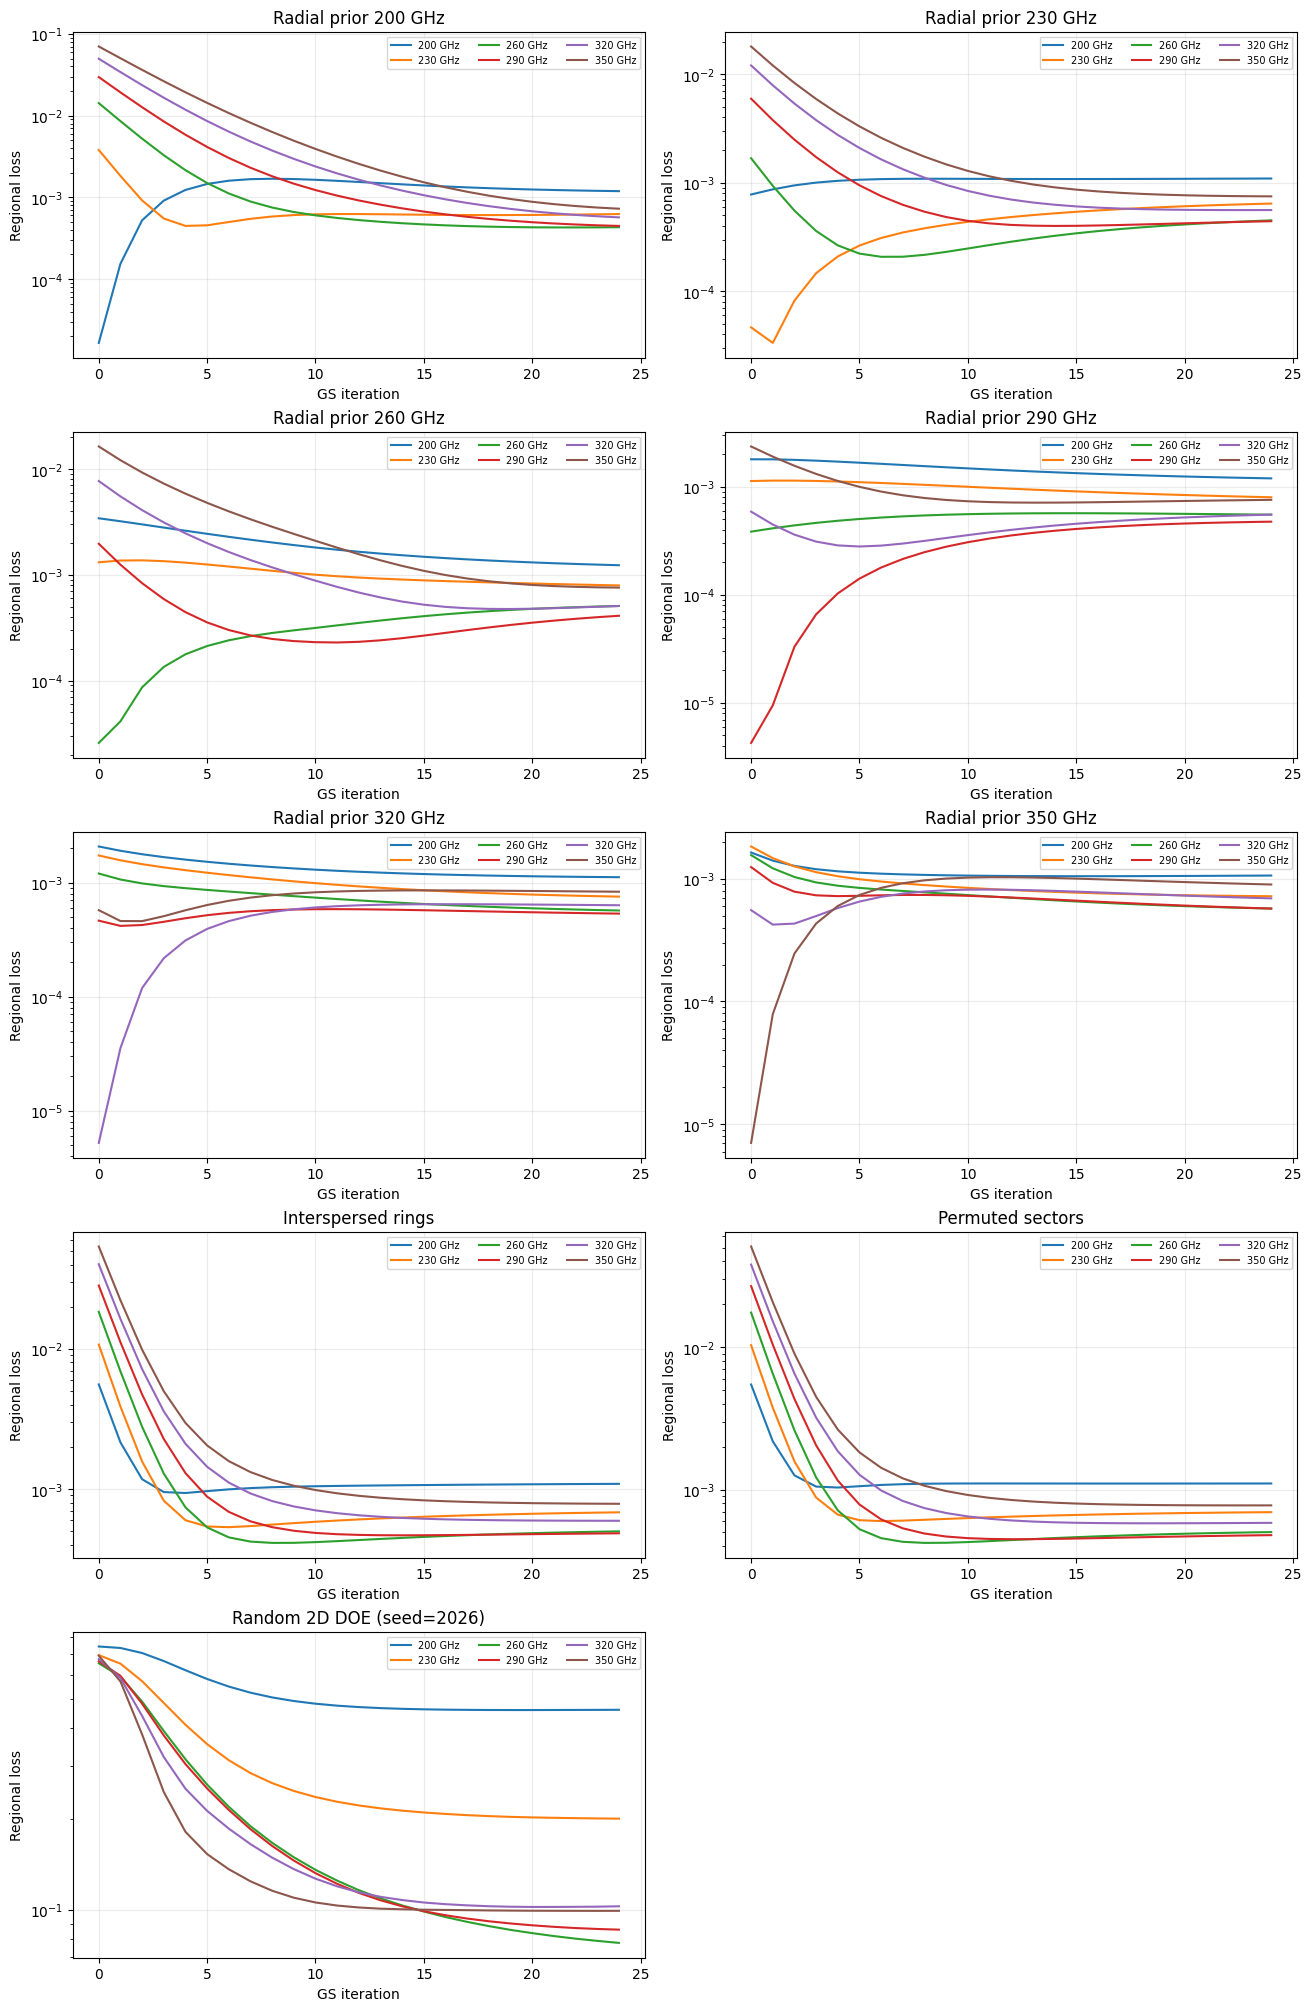

In [87]:
comparison_df = pd.concat([pre_metrics_df, post_metrics_df], ignore_index=True)
display(
    comparison_df.pivot_table(
        index=["layout", "frequency_GHz"],
        columns="stage",
        values=["rms", "ripple", "roi_efficiency"],
    ).round(4)
)

# Focused comparison of the random DOE against the radial-prior initializations.
metric_names = ["rms", "ripple", "roi_efficiency"]
radial_layout_names = [f"Radial prior {f:.0f} GHz" for f in FREQUENCIES_GHZ]

initial_comparison_rows = []
refined_comparison_rows = []
for f_GHz in FREQUENCIES_GHZ:
    f_GHz = float(f_GHz)

    # Prior-stage: compare random with the radial prior designed at this same frequency.
    random_pre = pre_metrics_df[
        (pre_metrics_df["layout"] == RANDOM_LAYOUT_NAME)
        & np.isclose(pre_metrics_df["frequency_GHz"], f_GHz)
    ].iloc[0]
    matched_radial_pre = pre_metrics_df[
        (pre_metrics_df["layout"] == f"Radial prior {f_GHz:.0f} GHz")
        & np.isclose(pre_metrics_df["frequency_GHz"], f_GHz)
    ].iloc[0]
    initial_comparison_rows.append({
        "frequency_GHz": f_GHz,
        **{f"random_{m}": float(random_pre[m]) for m in metric_names},
        **{f"matched_1D_prior_{m}": float(matched_radial_pre[m]) for m in metric_names},
    })

    # Refined stage: average over all six independently refined radial-prior starts.
    random_post = post_metrics_df[
        (post_metrics_df["layout"] == RANDOM_LAYOUT_NAME)
        & np.isclose(post_metrics_df["frequency_GHz"], f_GHz)
    ].iloc[0]
    radial_posts = post_metrics_df[
        post_metrics_df["layout"].isin(radial_layout_names)
        & np.isclose(post_metrics_df["frequency_GHz"], f_GHz)
    ]
    row = {"frequency_GHz": f_GHz}
    for m in metric_names:
        row[f"random_{m}"] = float(random_post[m])
        row[f"1D_starts_mean_{m}"] = float(radial_posts[m].mean())
        row[f"1D_starts_std_{m}"] = float(radial_posts[m].std(ddof=1))
    refined_comparison_rows.append(row)

initial_comparison_df = pd.DataFrame(initial_comparison_rows)
refined_comparison_df = pd.DataFrame(refined_comparison_rows)

print("\nBEFORE 2D OPTIMIZATION: random DOE vs frequency-matched 1D radial prior")
display(initial_comparison_df.round(4))

print("\nAFTER BROADBAND 2D OPTIMIZATION: random start vs six radial-prior starts")
display(refined_comparison_df.round(4))

print("\nFrequency-averaged summary")
summary_rows = []
for label, df, columns in [
    ("Random 2D DOE (before GS)", initial_comparison_df, "random"),
    ("Frequency-matched 1D prior (before GS)", initial_comparison_df, "matched_1D_prior"),
    ("Random 2D DOE (after GS)", refined_comparison_df, "random"),
    ("1D-prior starts (after GS; mean across six starts)", refined_comparison_df, "1D_starts_mean"),
]:
    summary_rows.append({
        "initialization": label,
        **{m: float(df[f"{columns}_{m}"].mean()) for m in metric_names},
    })
summary_comparison_df = pd.DataFrame(summary_rows)
display(summary_comparison_df.round(4))

# Plot loss evolution for every refined layout.
nrows = int(np.ceil(len(layout_names)/2))
fig, axes = plt.subplots(nrows, 2, figsize=(13, 4.0*nrows), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, name in zip(axes, layout_names):
    hist = gs_histories[name]
    for f_idx, f_GHz in enumerate(FREQUENCIES_GHZ):
        ax.semilogy(hist[:, f_idx] + 1e-15, label=f"{f_GHz:.0f} GHz")
    ax.set_title(name)
    ax.set_xlabel("GS iteration")
    ax.set_ylabel("Regional loss")
    ax.grid(alpha=0.25)
    ax.legend(ncol=3, fontsize=7)

for ax in axes[len(layout_names):]:
    ax.axis("off")
plt.show()

## 12. Final DOE phase maps and irradiance plots

The following cells produce the final 2D phase maps, per-frequency focal-plane irradiance maps, and frequency-overlaid center-line profiles for every layout. The same plotting functions are used for the unrefined priors and refined lenses, so the comparison is direct.

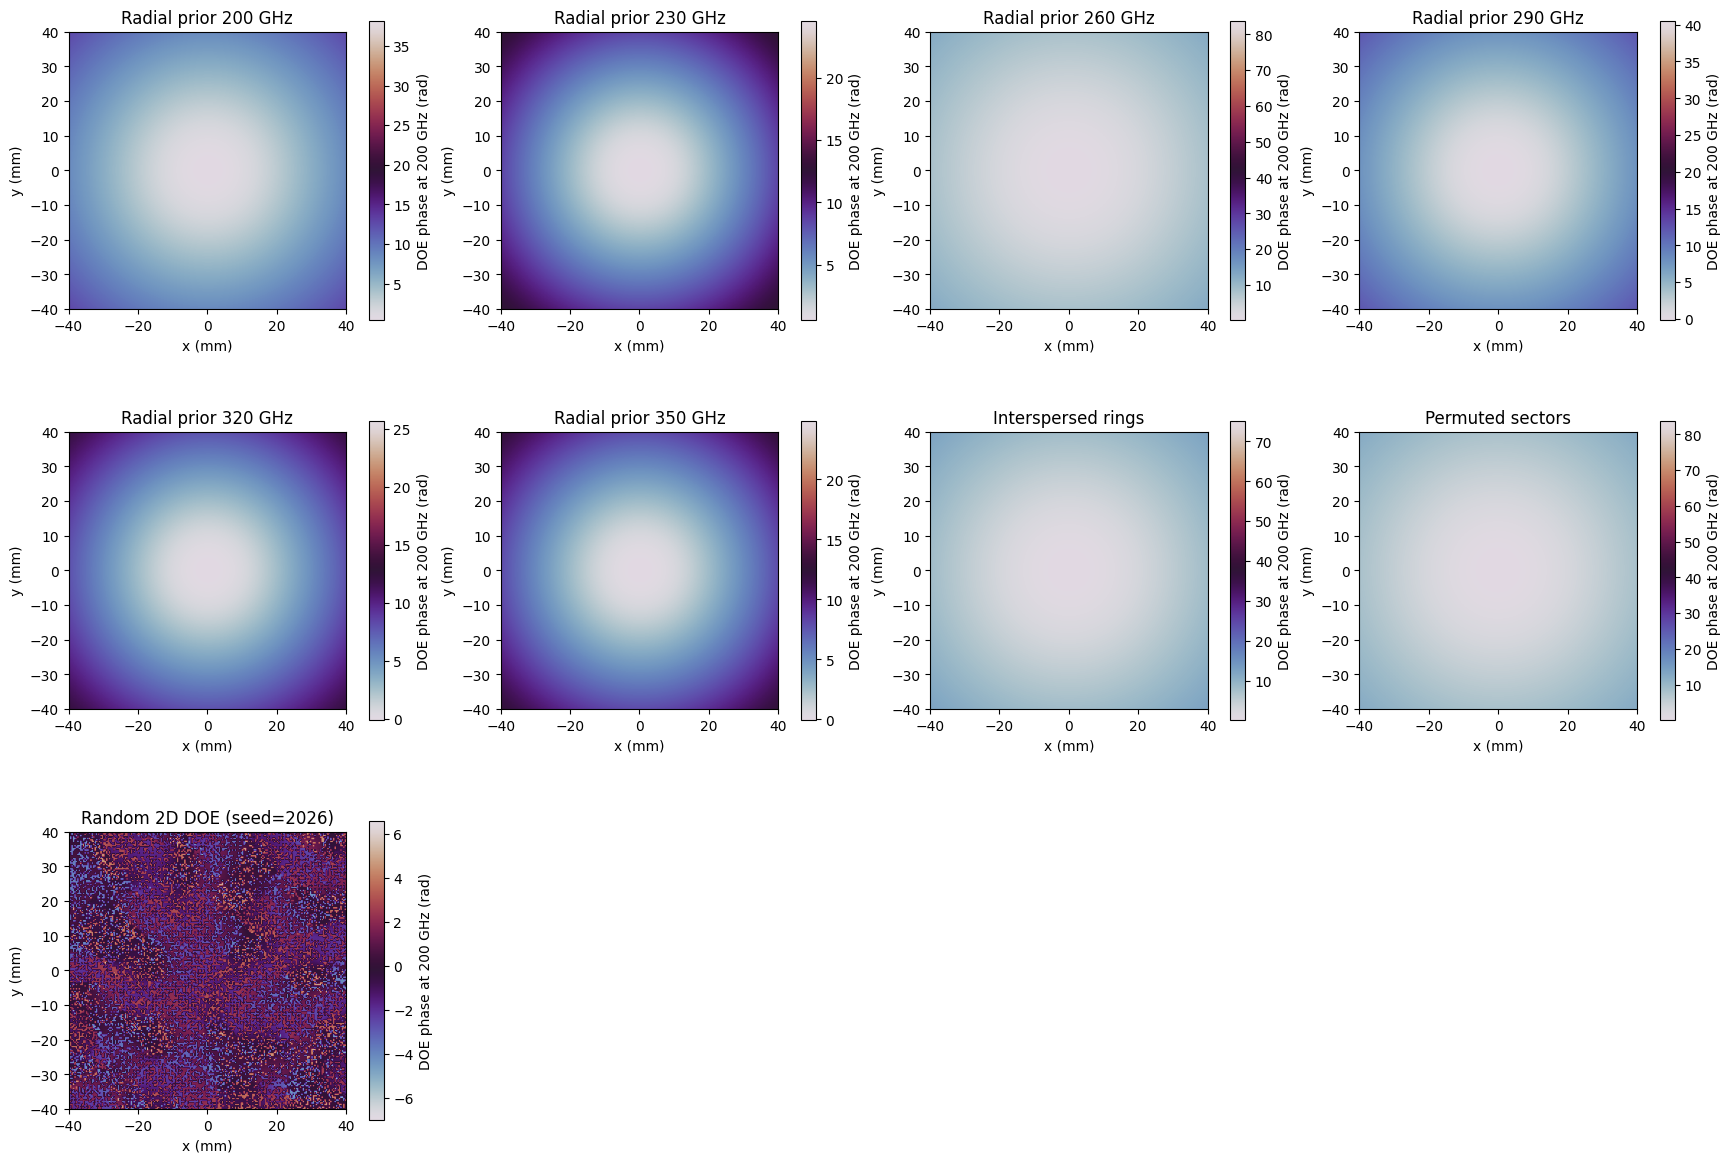

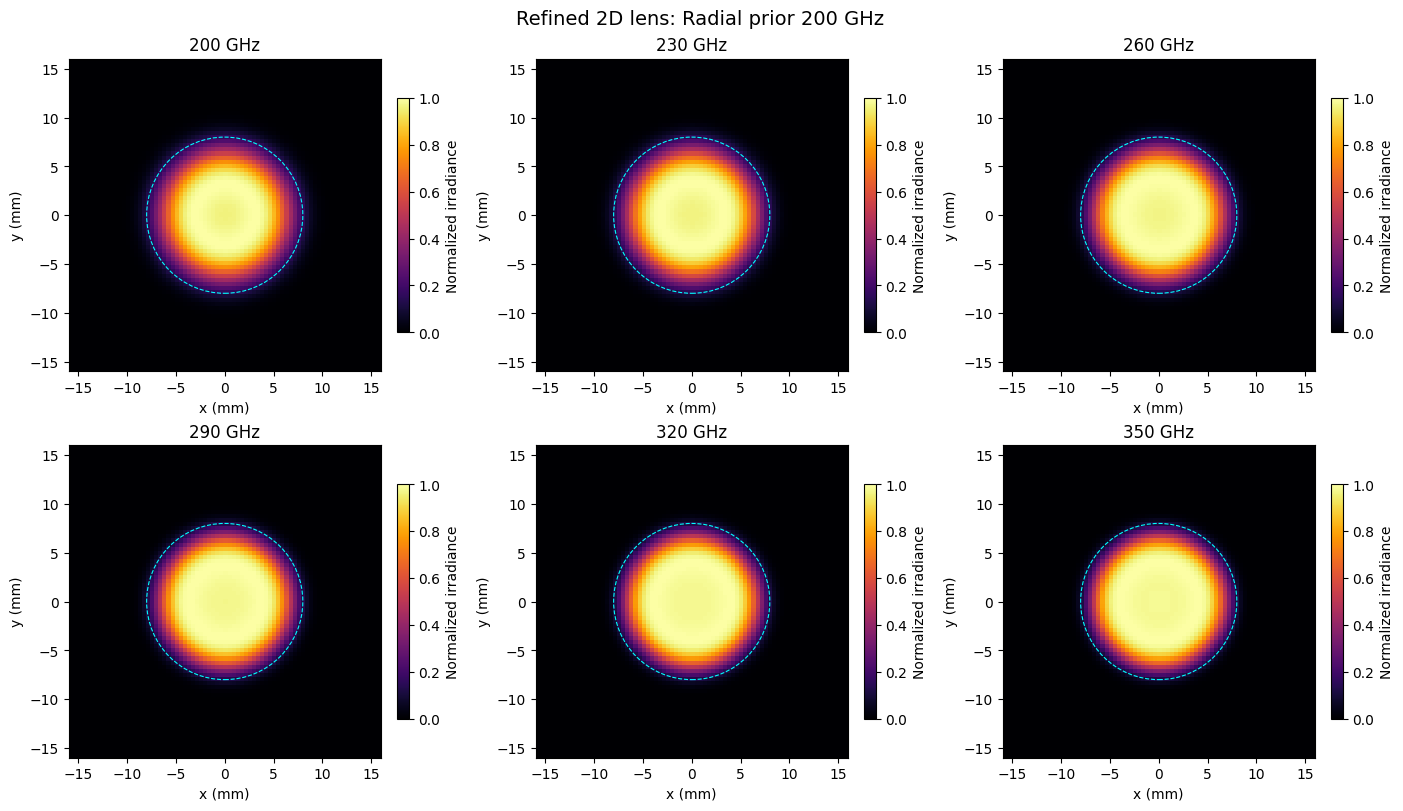

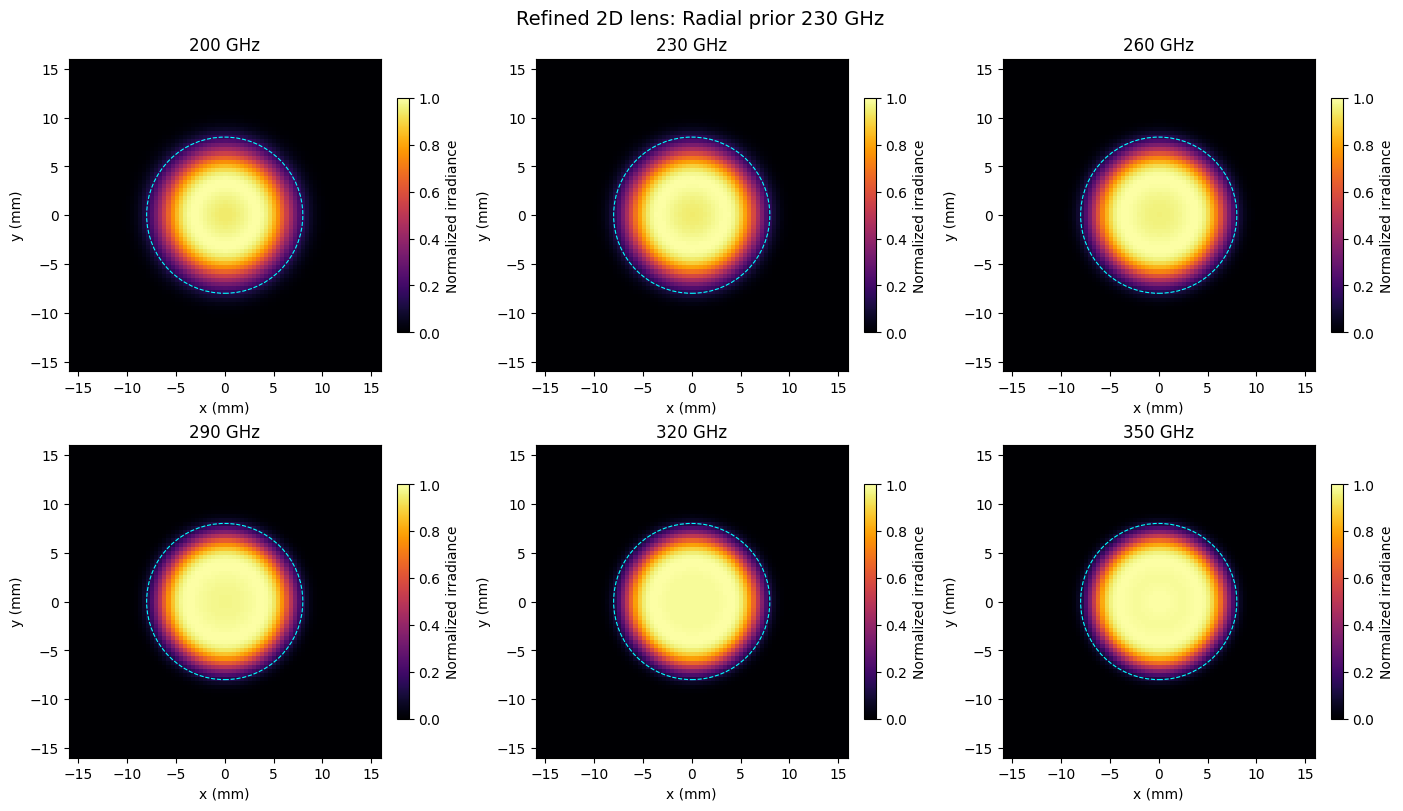

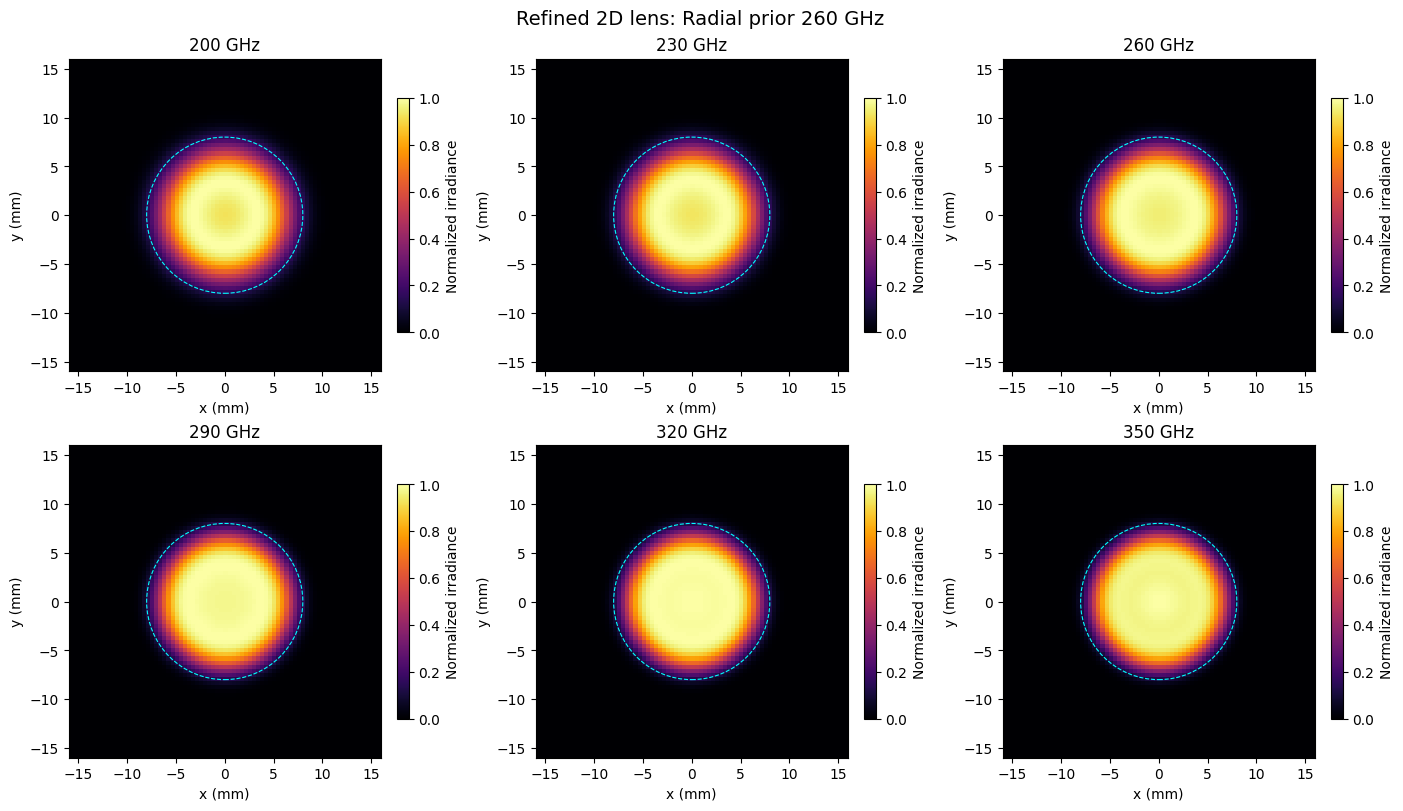

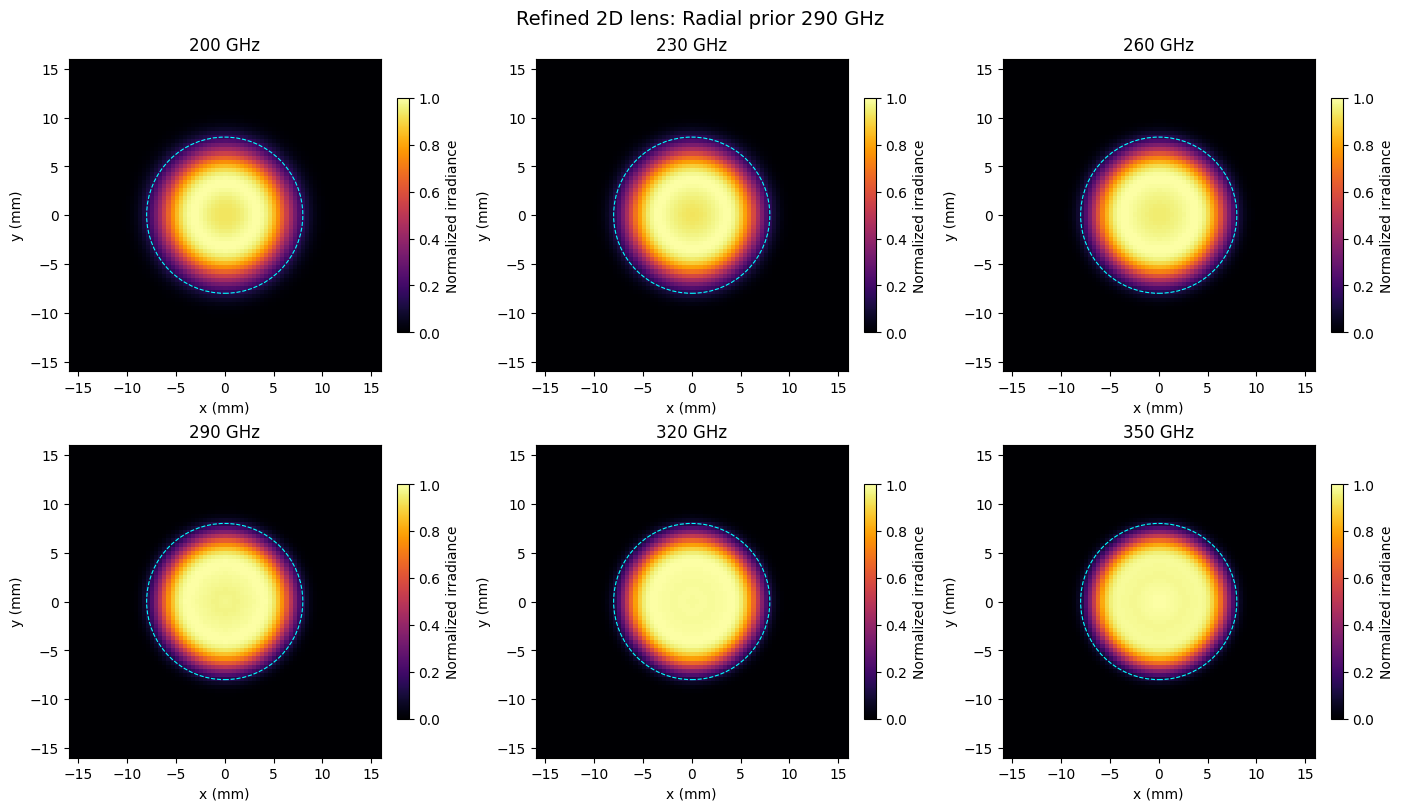

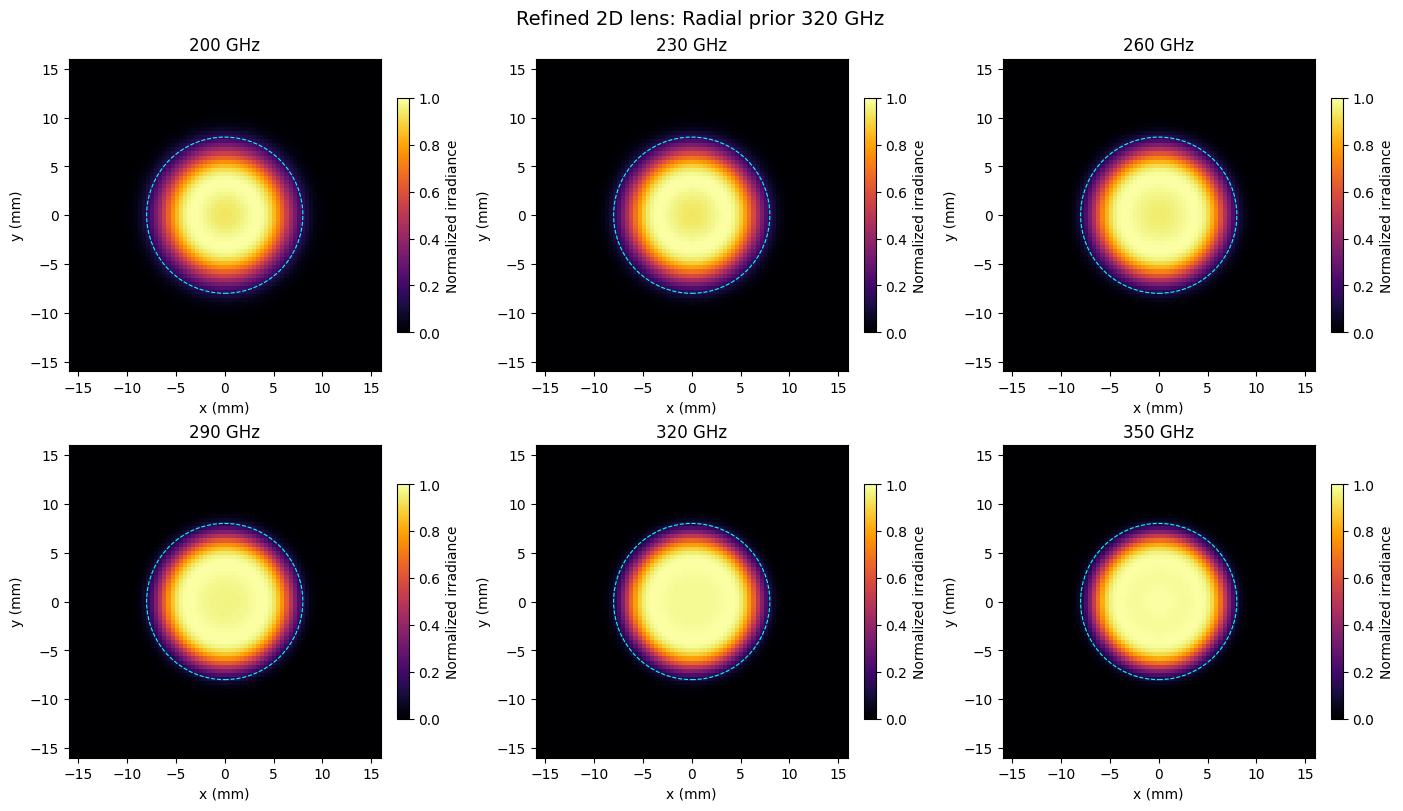

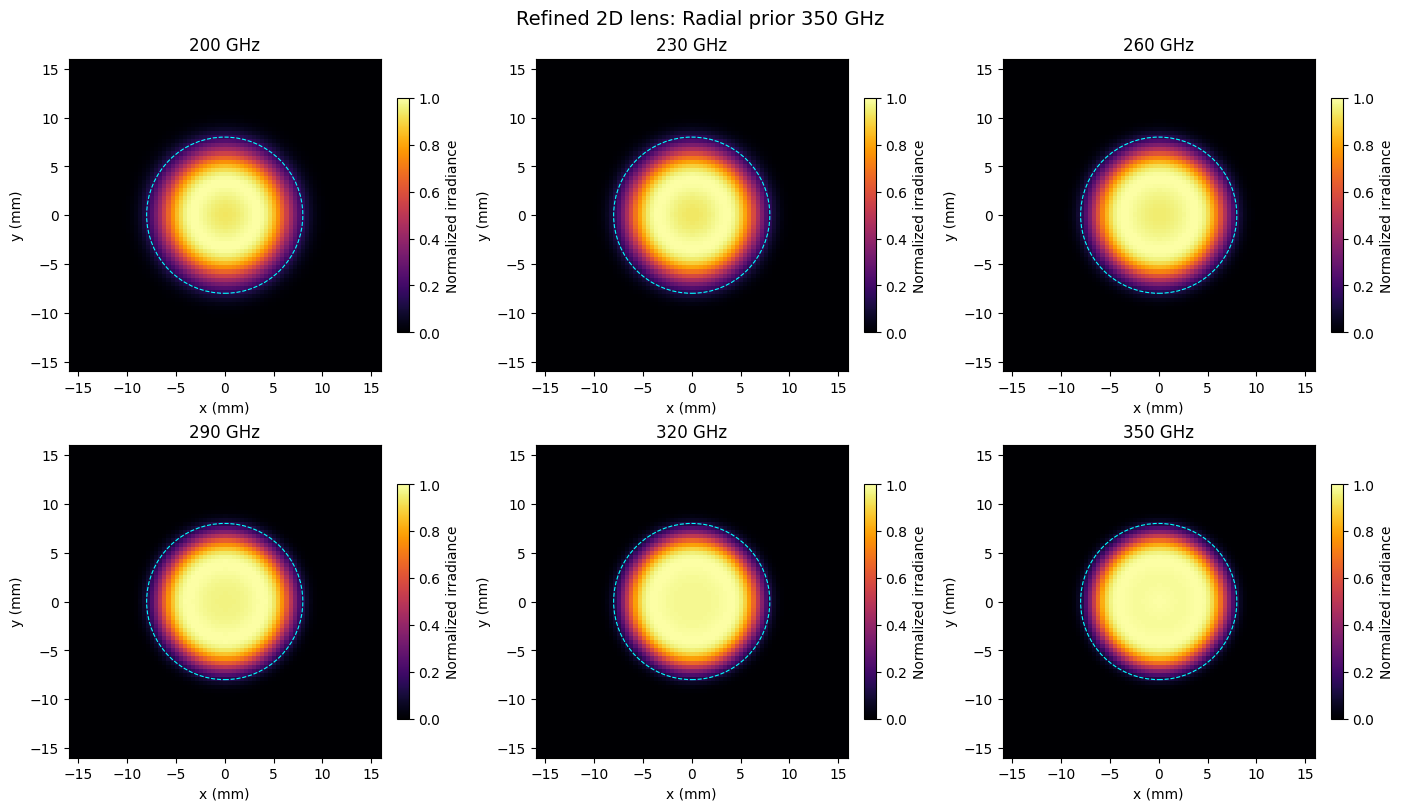

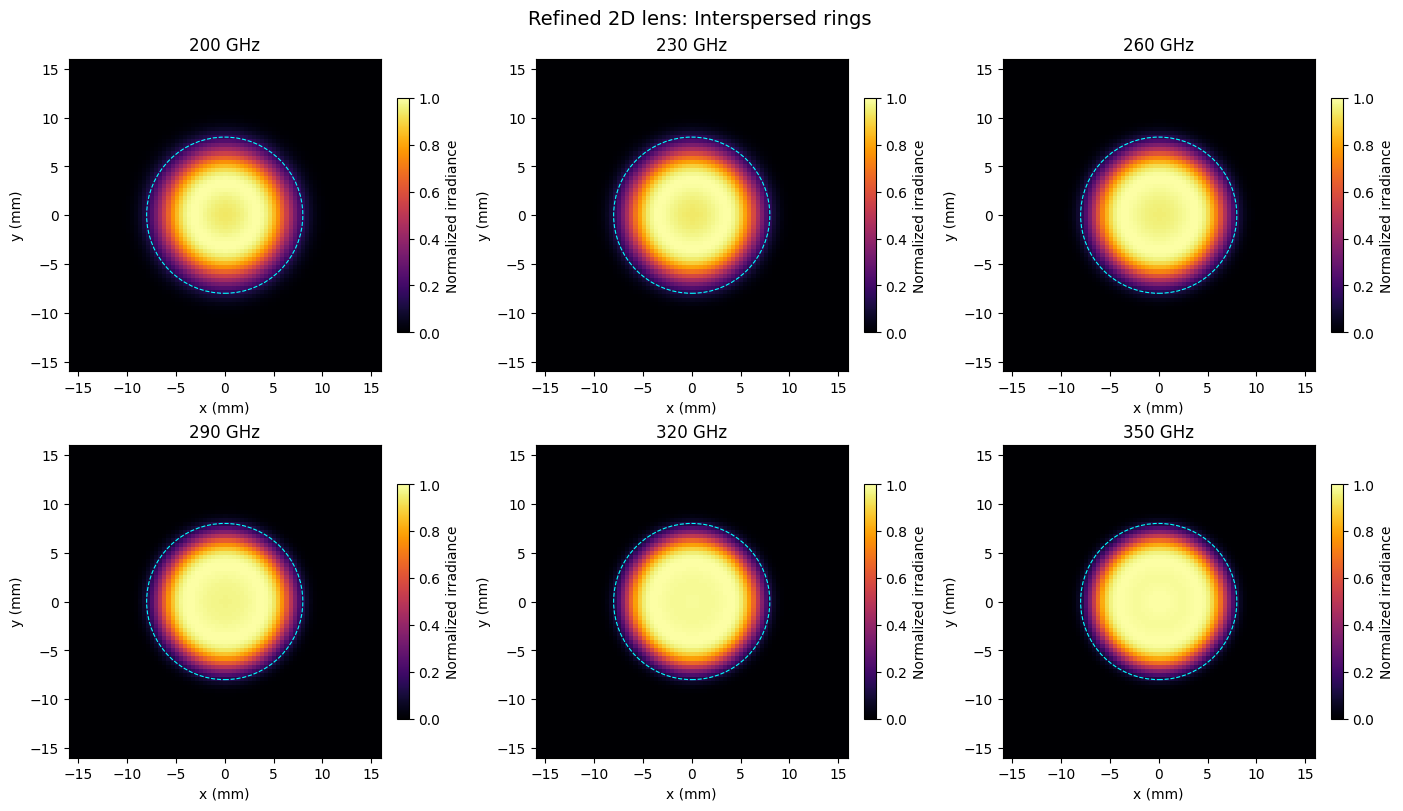

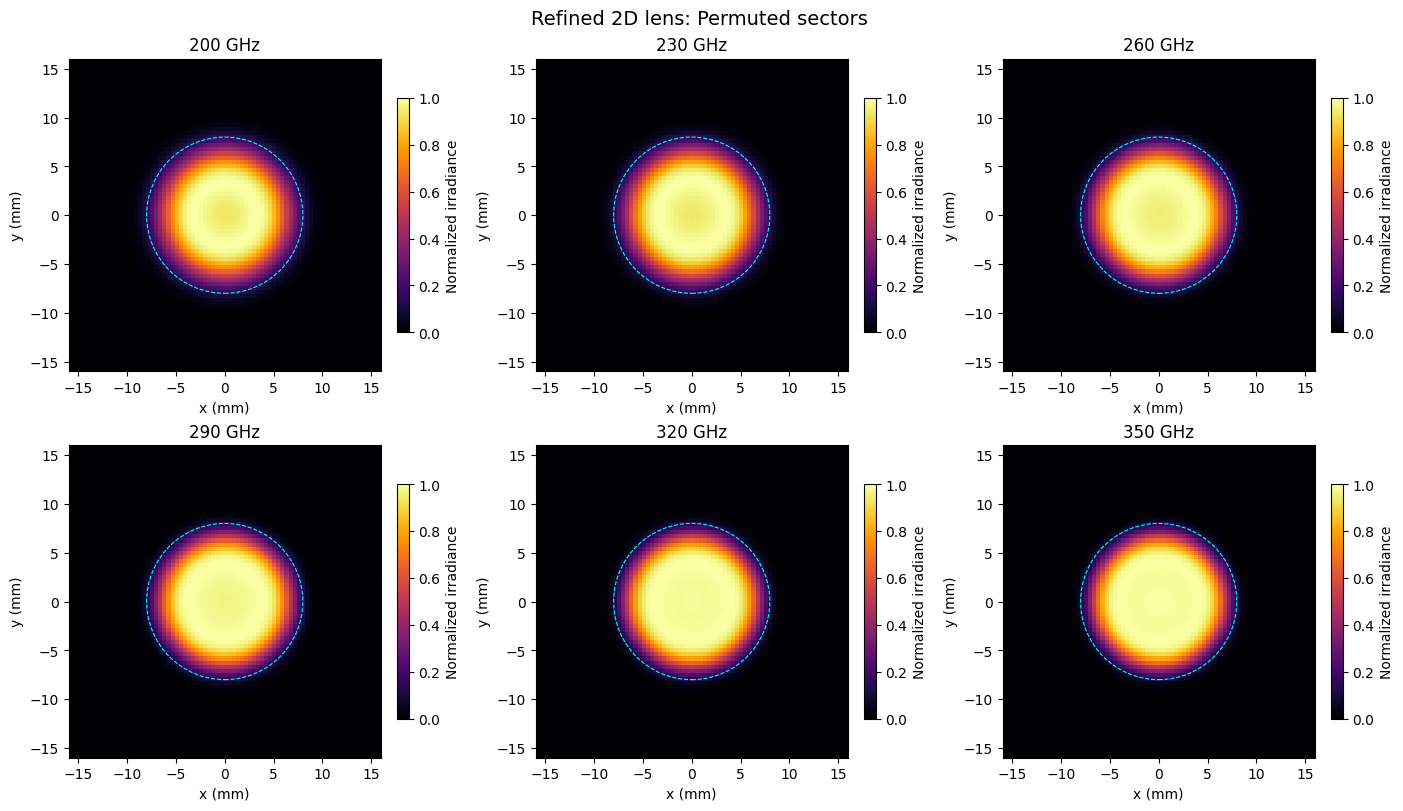

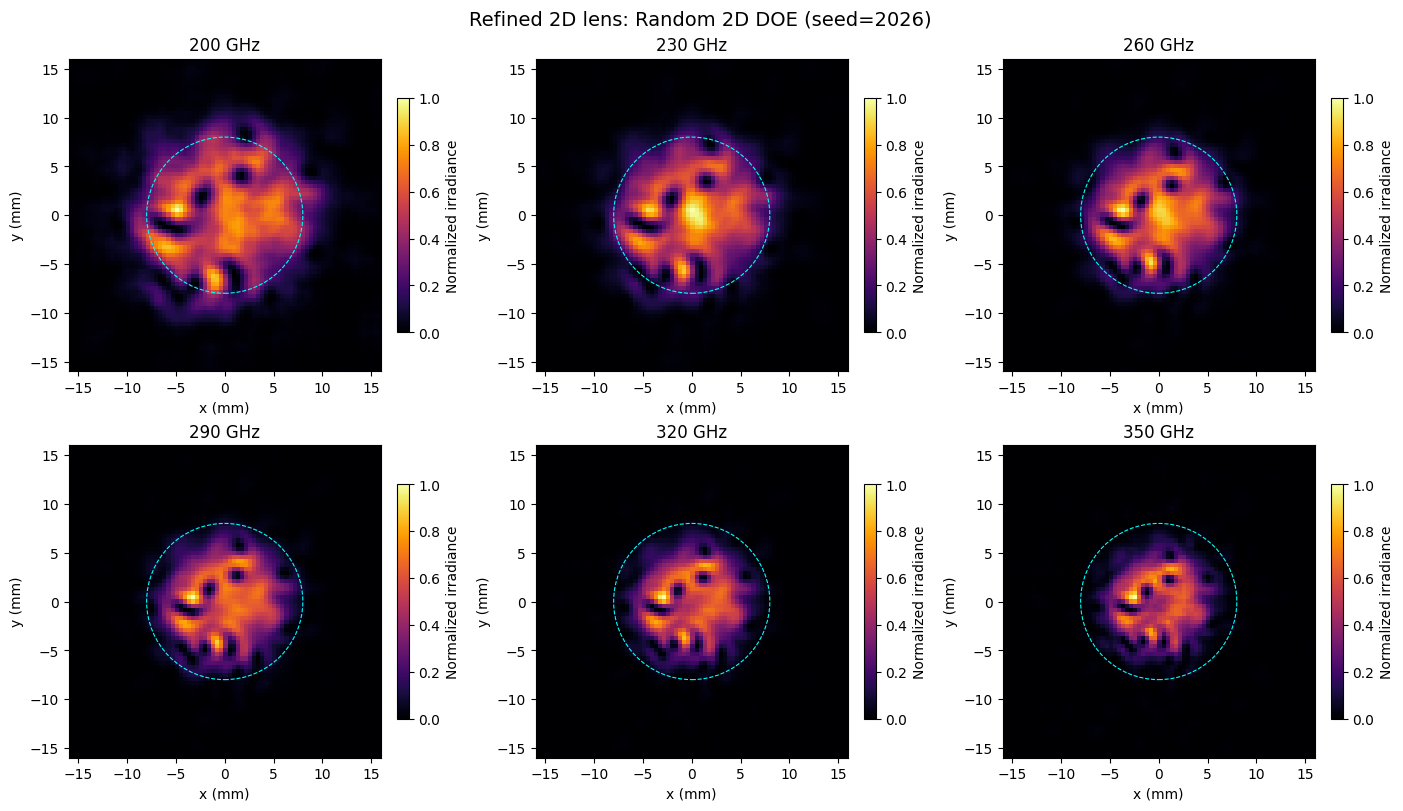

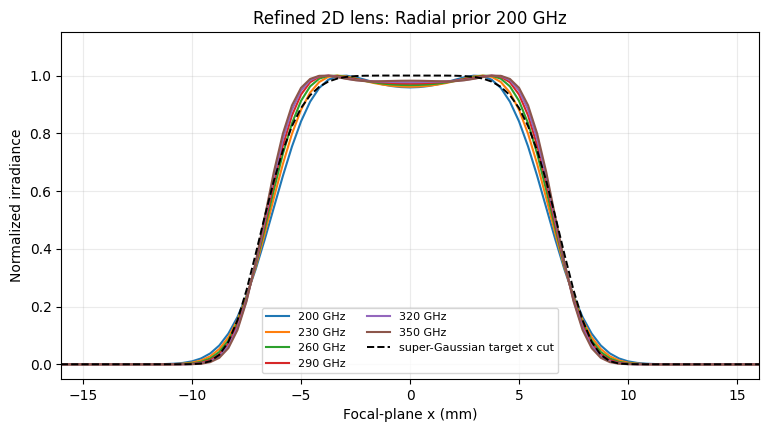

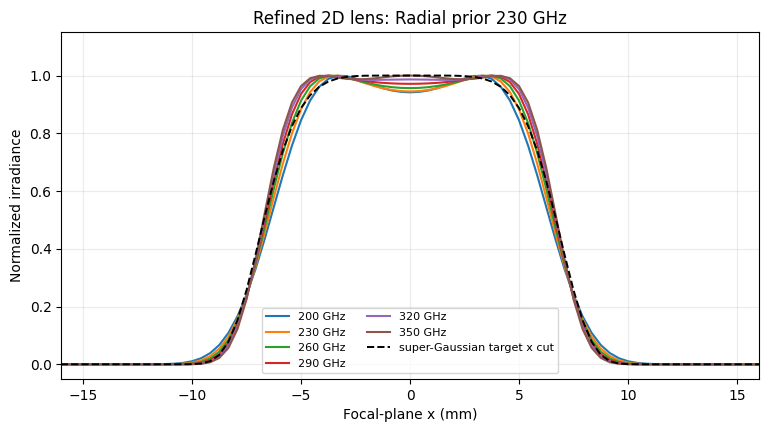

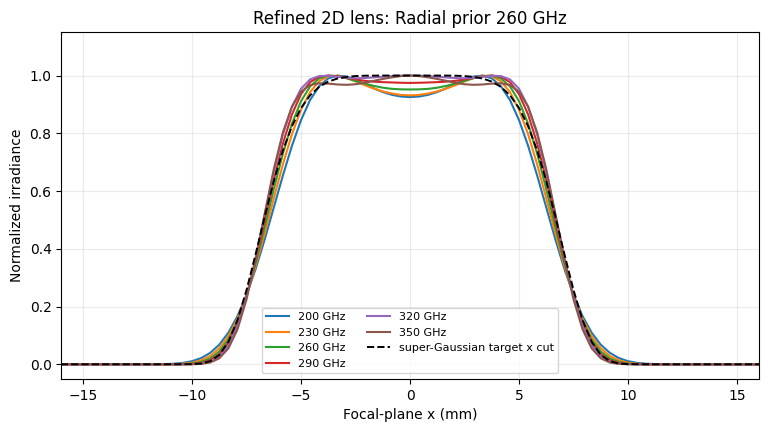

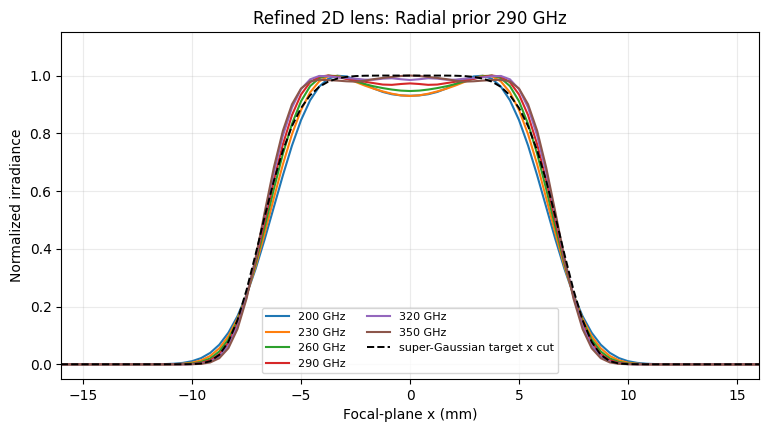

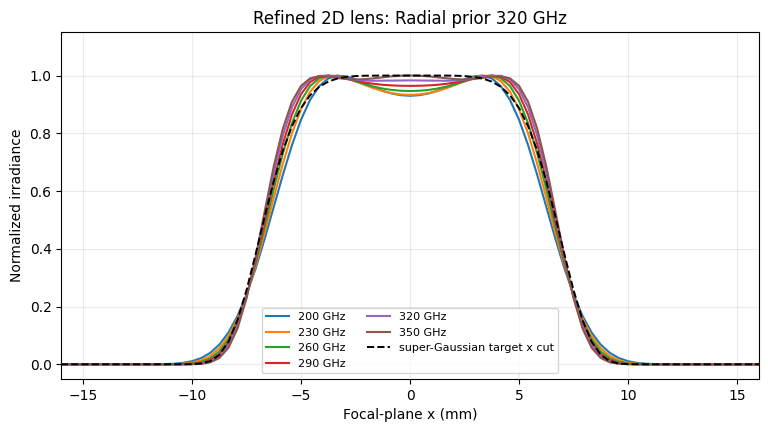

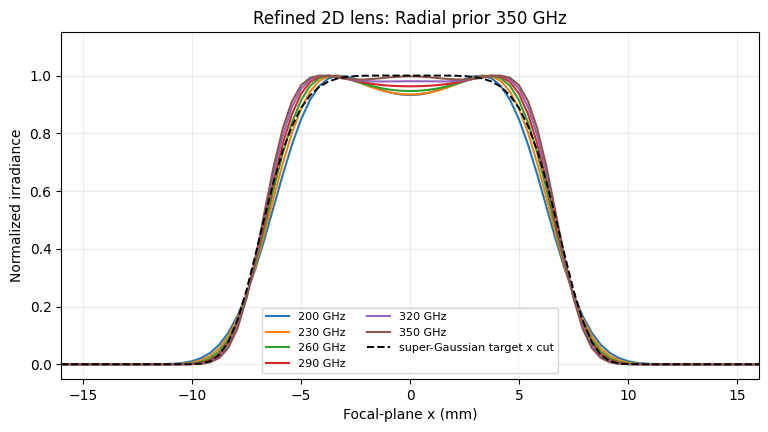

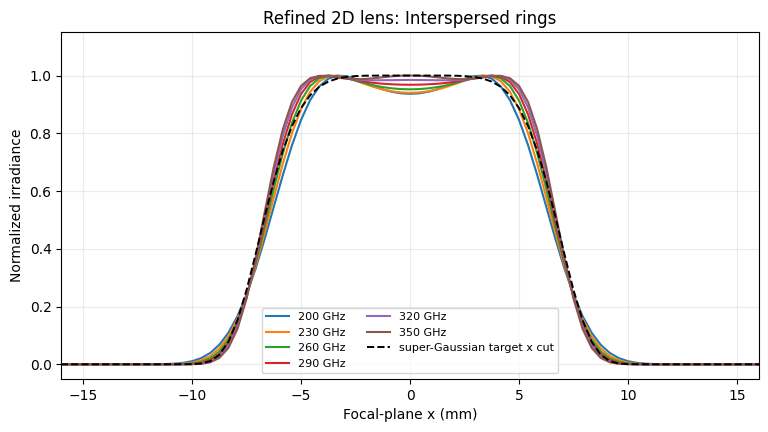

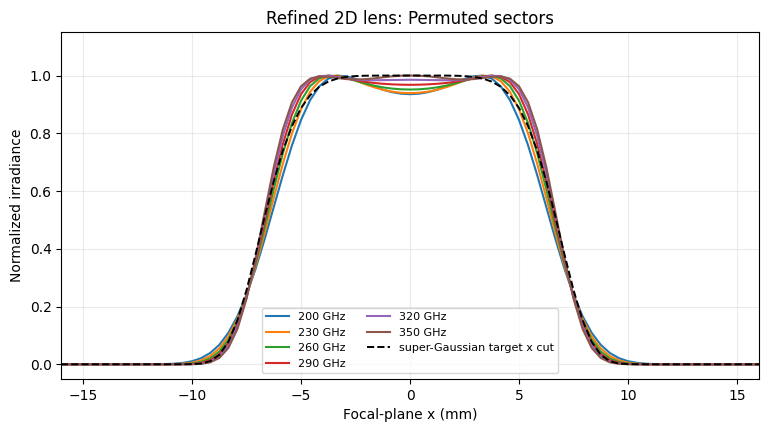

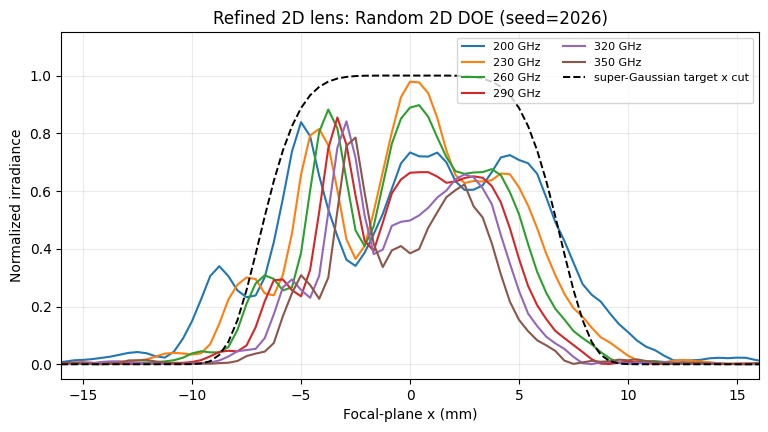

In [88]:
# Final reference-frequency DOE phase maps (lens phase is not included in these plots).
n_layouts = len(layout_names)
ncols = 4
nrows = int(np.ceil(n_layouts/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.3*ncols, 4.0*nrows), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, name in zip(axes, layout_names):
    im = ax.imshow(
        optimized_phases[name],
        extent=[coords_np[0], coords_np[-1], coords_np[0], coords_np[-1]],
        origin="lower",
        cmap="twilight",
    )
    ax.set_title(name)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    ax.set_xlim(-40, 40)
    ax.set_ylim(-40, 40)
    fig.colorbar(im, ax=ax, shrink=0.78, label=f"DOE phase at {F_REF_GHZ:.0f} GHz (rad)")

for ax in axes[len(layout_names):]:
    ax.axis("off")
plt.show()

plot_frequency_maps(optimized_outputs, "Refined 2D lens")
plot_frequency_cross_sections(optimized_outputs, "Refined 2D lens")

## 13. Summary and optional export

The phase arrays saved here are DOE-only phase maps at the reference frequency. The exact spherical focusing-lens phase is added separately during propagation, so it should also be included when constructing or simulating the complete optical system.

For a physical relief DOE with material dispersion, replace the nondispersive frequency scale
$$
s(f)=f/f_\mathrm{ref}
$$
by
$$
s(f)=\frac{f}{f_\mathrm{ref}}
\frac{n(f)-1}{n(f_\mathrm{ref})-1}.
$$
Measured refractive-index data are needed for that extension; no material model is assumed in this notebook. Likewise, a real refractive focusing lens may have a frequency-dependent focal length; this notebook follows the ideal fixed-focal-length lens assumption in the supplied 1D code.

The optional export cell writes the optimized DOE maps, 1D radial profiles, irradiance stacks, and metrics to files in the current Jupyter working directory.

In [89]:
EXPORT_RESULTS = False

if EXPORT_RESULTS:
    np.savez_compressed(
        "broadband_doe_1d_to_2d_ASM_results.npz",
        frequencies_GHz=FREQUENCIES_GHZ,
        reference_frequency_GHz=F_REF_GHZ,
        radial_grid_1d=one_d_designs[float(FREQUENCIES_GHZ[0])]["problem"].r,
        native_1d_phases=np.stack([
            phi_doe_native[float(f)] for f in FREQUENCIES_GHZ
        ]),
        reference_1d_phases=np.stack([
            phi_doe_reference[float(f)] for f in FREQUENCIES_GHZ
        ]),
        x_grid_2d_mm=coords_np,
        layout_names=np.asarray(layout_names),
        prior_phase_maps=np.stack([layout_phases[name] for name in layout_names]),
        optimized_phase_maps=np.stack([optimized_phases[name] for name in layout_names]),
        prior_irradiances=np.stack([pre_optimization_outputs[name] for name in layout_names]),
        optimized_irradiances=np.stack([optimized_outputs[name] for name in layout_names]),
    )
    comparison_df.to_csv("broadband_doe_1d_to_2d_ASM_metrics.csv", index=False)
    print("Exported broadband_doe_1d_to_2d_ASM_results.npz and metrics CSV.")
else:
    print("Set EXPORT_RESULTS = True to save arrays and metrics.")

Set EXPORT_RESULTS = True to save arrays and metrics.
